# Machine Learning - Assignment3
# Noura Khdour - Enas Qutit - Aseel Dar Assi

# Extract the ZIP file

In [ ]:
import zipfile
import os
from pathlib import Path
from datetime import datetime
import shutil
import pandas as pd
import re


In [ ]:
ZIP_PATH = "data_compressed.zip"
EXTRACT_DIR = "extracted_data"
OUTPUT_FOLDER = "csv_files"


# === Step 1: Extract zip file ===
if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR)

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction finished.")


#==== step 2: GET NEWEST FILE FROM EACH FOLDER ====

file_count = 0
folder_count = 0

# Walk through all folders
for root, dirs, files in os.walk(EXTRACT_DIR):
    # Find CSV/XLS/XLSX files in this folder ONLY (not subfolders)
    data_files = [f for f in files if f.endswith(('.csv', '.xls', '.xlsx','.txt'))]

    if data_files:
        folder_count += 1

        # Find the NEWEST file by modification time
        newest_file = None
        newest_time = None

        for file in data_files:
            file_path = os.path.join(root, file)
            mod_time = os.path.getmtime(file_path)

            if newest_time is None or mod_time > newest_time:
                newest_time = mod_time
                newest_file = file

        # Copy only the newest file
        source = os.path.join(root, newest_file)
        dest = os.path.join(OUTPUT_FOLDER, f"folder_{folder_count}_{newest_file}")
        shutil.copy2(source, dest)
        file_count += 1

        if len(data_files) > 1:
            print(f"Folder {folder_count}: Found {len(data_files)} files → Kept newest: {newest_file}")
        else:
            print(f"Folder {folder_count}: {newest_file}")

print(f"\n✅ Total files copied: {file_count}")
print(f"✅ Total folders processed: {folder_count}")




Extraction finished.
Folder 1: 2936035-1161937.csv
Folder 2: 2938271-1181804.csv
Folder 3: 2935882-1190408.xlsx
Folder 4: Found 2 files → Kept newest: 2937999-1190855.csv
Folder 5: 2938087-1200242.csv
Folder 6: 2934979-1200431.csv
Folder 7: 2938588-1200964 .csv
Folder 8: 2937520-1201169.csv
Folder 9: 2938444-1201208.csv
Folder 10: 2938327-StudentID.csv
Folder 11: 2935801-1201261.csv
Folder 12: 2938388-1201768 .csv
Folder 13: 2938253-1201862.csv
Folder 14: 2938317-HalaMosafer1202223.csv
Folder 15: 2938246-1202251.csv
Folder 16: 2937992-1202450.csv
Folder 17: 2935939-1203048.csv
Folder 18: 2934677-1210084.csv
Folder 19: 2938366-1210123.csv
Folder 20: 2935410-1210221.csv
Folder 21: Found 2 files → Kept newest: 2936661-1210236.csv
Folder 22: 2933301-1210241.csv.xlsx
Folder 23: 2938460-1210249.csv
Folder 24: 2938282-1210326.csv
Folder 25: 2938501-1210420.csv
Folder 26: 2938360-1210472.csv.xlsx
Folder 27: 2934259-1210574.csv
Folder 28: 2938133-1210582.csv
Folder 29: 2938113-1210618.csv
Folde

In [ ]:
FINAL_OUTPUT = "combined_data.csv"

FINAL_COLUMNS = [
    'image_url',
    'description',
    'country',
    'weather',
    'time_of_day',
    'season',
    'activity',
    'mood_emotion'
]

# Map all possible column names to standard names
COLUMN_MAP = {
    'image url': 'image_url',
    'image_url': 'image_url',
    'image link': 'image_url',
    'url': 'image_url',
    'image': 'image_url',

    'desc': 'description',
    'description': 'description',
    'image description': 'description',
    'caption': 'description',

    'country': 'country',
    'location': 'country',
    'place': 'country',

    'weather': 'weather',
    'condition': 'weather',
    'weather condition': 'weather',

    'time': 'time_of_day',
    'time of day': 'time_of_day',
    'time_of_day': 'time_of_day',
    'timeofday': 'time_of_day',

    'season': 'season',

    'activity': 'activity',
    'action': 'activity',
    'activities': 'activity',

    'mood': 'mood_emotion',
    'emotion': 'mood_emotion',
    'mood emotion': 'mood_emotion',
    'mood/emotion': 'mood_emotion',
    'emotion/mood': 'mood_emotion',
    'feeling': 'mood_emotion'
}

# ============================================
# STEP 2: NORMALIZE COLUMN NAMES
# ============================================

def normalize_column(col):
    """Convert any column name to standard format"""
    col = col.lower().strip()
    col = re.sub(r'[:/_\-]', ' ', col)  # Replace special chars with space
    col = re.sub(r'\s+', ' ', col)      # Remove extra spaces
    return col

# ============================================
# STEP 3: READ + NORMALIZE FILES
# ============================================

print("="*80)
print("📂 READING AND COMBINING FILES")
print("="*80 + "\n")

all_data = []
successful = 0
failed = 0

# List all files in folder
files_to_process = os.listdir(OUTPUT_FOLDER)

for file in files_to_process:
    path = os.path.join(OUTPUT_FOLDER, file)

    # Skip if not a file
    if not os.path.isfile(path):
        continue

    # Skip unsupported formats
    if not file.endswith(('.csv', '.txt', '.xls', '.xlsx')):
        continue

    try:
        print(f"Reading: {file}...", end=" ")

        df = None
        encoding_used = None

        # Handle Excel files
        if file.endswith(('.xls', '.xlsx')):
            try:
                df = pd.read_excel(path)
                encoding_used = "Excel"
            except Exception as e:
                raise Exception(f"Excel read error: {str(e)}")

        # Handle CSV and TXT files
        else:
            encodings = ['utf-8', 'latin1', 'iso-8859-1', 'cp1252', 'utf-16']
            df = None
            encoding_used = None

            for enc in encodings:
                try:
                    df = pd.read_csv(path, encoding=enc, on_bad_lines='skip', engine='python')
                    encoding_used = enc
                    break
                except Exception:
                    continue

            if df is None:
                # Try reading as plain text with different delimiters
                for delimiter in [',', ';', '\t', '|']:
                    try:
                        df = pd.read_csv(path, encoding='utf-8', delimiter=delimiter, on_bad_lines='skip', engine='python')
                        if len(df) > 0:
                            encoding_used = f"utf-8 (delimiter: {delimiter})"
                            break
                    except:
                        continue

            if df is None:
                raise Exception("Could not read with any encoding or delimiter")

        # Check if dataframe is empty or has no rows
        if len(df) == 0 or df.shape[0] == 0:
            raise Exception("File is empty (0 rows)")

        # Check if dataframe has columns
        if len(df.columns) == 0:
            raise Exception("File has no columns")

        # Map columns to standard names
        extracted = {}

        for col in df.columns:
            normalized_key = normalize_column(col)

            # Check if this column matches any mapping
            if normalized_key in COLUMN_MAP:
                canonical = COLUMN_MAP[normalized_key]
                extracted[canonical] = df[col].values
            else:
                # Try partial matching for complex names
                found = False
                for mapped_key, canonical in COLUMN_MAP.items():
                    if mapped_key in normalized_key or normalized_key in mapped_key:
                        if canonical not in extracted:  # Don't overwrite
                            extracted[canonical] = df[col].values
                            found = True
                            break

        # Ensure all required columns exist
        for col in FINAL_COLUMNS:
            if col not in extracted:
                extracted[col] = [""] * len(df)  # Fill with empty list

        # Create dataframe with only final columns
        clean_df = pd.DataFrame(extracted)
        clean_df = clean_df[FINAL_COLUMNS]

        all_data.append(clean_df)
        successful += 1

        print(f"✅ ({len(df)} rows)")

    except Exception as e:
        failed += 1
        print(f"❌ Error: {str(e)}")

# ============================================
# STEP 4: COMBINE ALL DATA
# ============================================

print("\n" + "="*80)
print("🔗 COMBINING ALL DATA")
print("="*80 + "\n")

if not all_data:
    print("❌ No files were successfully read!")
    exit()

final_df = pd.concat(all_data, ignore_index=True)
final_df = final_df[FINAL_COLUMNS]

print(f"✅ Successfully combined: {successful} files")
print(f"❌ Failed files: {failed}")
print(f"\nTotal rows: {len(final_df)}")
print(f"Total columns: {len(final_df.columns)}")

📂 READING AND COMBINING FILES

Reading: folder_100_2938577-1221350.csv... ✅ (10 rows)
Reading: folder_101_2938478-1221574.csv... ✅ (10 rows)
Reading: folder_102_2934909-1221636.csv.txt... ✅ (10 rows)
Reading: folder_103_2938180-1221697.csv... ✅ (10 rows)
Reading: folder_104_2934914-1221808.csv... ✅ (10 rows)
Reading: folder_105_2938653-1221899.csv... ✅ (10 rows)
Reading: folder_106_2938496-1221916.csv... ✅ (10 rows)
Reading: folder_107_2938660-1221998.csv... ✅ (63 rows)
Reading: folder_108_2935454-1222018.csv... ✅ (10 rows)
Reading: folder_109_2937019-1222332.csv... ✅ (10 rows)
Reading: folder_10_2938327-StudentID.csv... ✅ (10 rows)
Reading: folder_110_2935602-1222640 - Sheet1.csv... ✅ (10 rows)
Reading: folder_11_2935801-1201261.csv... ✅ (10 rows)
Reading: folder_12_2938388-1201768 .csv... ✅ (10 rows)
Reading: folder_13_2938253-1201862.csv... ✅ (10 rows)
Reading: folder_14_2938317-HalaMosafer1202223.csv... ✅ (10 rows)
Reading: folder_15_2938246-1202251.csv... ✅ (10 rows)
Reading: fold

In [ ]:
print("\n" + "="*80)
print("💾 SAVING FINAL FILE")
print("="*80 + "\n")

try:
    final_df.to_csv(FINAL_OUTPUT, index=False)

    # Verify file was created
    if os.path.exists(FINAL_OUTPUT):
        file_size = os.path.getsize(FINAL_OUTPUT)
        print(f"✅ Successfully saved: {FINAL_OUTPUT}")
        print(f"   Size: {file_size:,} bytes")
        print(f"   Rows: {len(final_df)}")
        print(f"   Columns: {len(final_df.columns)}")
        print(f"   Location: {os.path.abspath(FINAL_OUTPUT)}")
    else:
        print(f"❌ File was not created!")

except Exception as e:
    print(f"❌ Error saving file: {str(e)}")
    exit()


💾 SAVING FINAL FILE

✅ Successfully saved: combined_data.csv
   Size: 321,336 bytes
   Rows: 1499
   Columns: 8
   Location: C:\Users\SS\PycharmProjects\ML_Pro1\combined_data.csv


# Preprocessing the data

In [ ]:
import pandas as pd
import re
import os
import requests
from PIL import Image
from io import BytesIO
import numpy as np
from pathlib import Path
from sklearn.preprocessing import StandardScaler

In [ ]:
myfile = pd.read_csv(r'C:\Users\SS\Downloads\combined_data.csv')
df=myfile.copy()

In [ ]:
df = df.drop(columns=["Unnamed: 8", "Unnamed: 9", "Unnamed: 10"])

df.isnull().sum()


image_url        0
description      7
country          1
weather          0
time_of_day      0
season           0
activity        21
mood_emotion     5
dtype: int64

In [ ]:
# check duplicate URL links
# remove the duplicate URL links
df =df.drop_duplicates(subset=["image_url"])
print("After removing duplicates:number of unique links ", len(df))
print(df['weather'].value_counts())


After removing duplicates:number of unique links  1017
weather
Sunny                         518
Cloudy                        198
Snowy                          76
Not Clear                      75
Clear                          49
Rainy                          22
sunny                          11
cloudy                         10
Not clear                       6
Clear / Sunny                   5
 Sunny                          5
 Cloudy                         4
 sunny                          4
not clear                       3
snowy                           3
Sunny                           2
Windy                           2
Cold                            2
Partly Cloudy                   2
 raniy                          2
 not clear                      2
 Not clear                      2
 snowy                          2
Clear Night Sky                 1
Not Clear (night lighting)      1
Cloudy Sunset                   1
Clear Night                     1
 Not Clear         

In [ ]:
#standrize the weather
# Map all possible weather variations to standard categories
WEATHER_MAPPINGS = {
    # --- SUNNY / CLEAR variations ---
    'Sunny': 'Sunny',
    'sunny': 'Sunny',
    ' sunny': 'Sunny',
    'sunny ': 'Sunny',
    'Sunny ': 'Sunny',
    ' Sunny': 'Sunny',
    'Clear': 'Sunny',
    'clear': 'Sunny',
    ' Clear': 'Sunny',
    'clear ': 'Sunny',
    'Sunny\\t': 'Sunny',
    'Clear / Sunny': 'Sunny',
    'Clear Night Sky': 'Sunny',
    'Clear Night': 'Sunny',

    # --- CLOUDY / WINDY / COLD variations ---
    'Cloudy': 'Cloudy',
    'cloudy': 'Cloudy',
    ' Cloudy': 'Cloudy',
    'cloudy ': 'Cloudy',
    'Cloudy ': 'Cloudy',
    ' Partly Cloudy': 'Cloudy',
    'Partly Cloudy': 'Cloudy',
    'Partly Cloudy / Sunny': 'Cloudy',
    'Cloudy Sunset': 'Cloudy',
    'Cloudt': 'Cloudy',
    'Windy': 'Cloudy',
    'windy': 'Cloudy',
    'Cold': 'Cloudy',

    # --- RAINY variations ---
    'Rainy': 'Rainy',
    'rainy': 'Rainy',
    ' raniy': 'Rainy',  # Typo from image
    'raniy': 'Rainy',   # Typo from image

    # --- SNOWY variations ---
    'Snowy': 'Snowy',
    'snowy': 'Snowy',
    ' snowy': 'Snowy',
    'snowy ': 'Snowy',

    # --- NOT CLEAR variations ---
    'Not Clear': 'Not Clear',
    'Not clear': 'Not Clear',
    'not clear': 'Not Clear',
    'no clear ': 'Not Clear',
    ' not clear': 'Not Clear',
    ' Not Clear': 'Not Clear',
    'no clear': 'Not Clear',
    'Not Clear (night lighting)': 'Not Clear',
}



def standardize_weather(weather_value):
    """
    Standardize weather value to one of 5 categories:
    - Sunny
    - Rainy
    - Cloudy
    - Snowy
    - Not Clear
    """

    if pd.isna(weather_value):
        return 'Not Clear'

    # Convert to string, lowercase, and strip whitespace
    weather_str = str(weather_value).lower().strip()

    # First, check for exact matches
    if weather_str in WEATHER_MAPPINGS:
        return WEATHER_MAPPINGS[weather_str]

    # Then, check for partial matches, prioritizing longer keys
    # (this prevents "clear" from matching "not clear")
    sorted_keys = sorted(WEATHER_MAPPINGS.keys(), key=len, reverse=True)

    for key in sorted_keys:
        if key in weather_str:
            return WEATHER_MAPPINGS[key]

    # If no match found, return 'Not Clear' as default
    return 'Not Clear'

# Example usage:
df['weather'] = df['weather'].apply(standardize_weather)
print(df['weather'].value_counts())



weather
Sunny        598
Cloudy       220
Not Clear     94
Snowy         81
Rainy         24
Name: count, dtype: int64


In [ ]:

IMAGES_FOLDER = "images_2"
MAX_IMAGES = None


weather_types = sorted(df['weather'].unique())
print(f"Weather categories: {len(weather_types)}\n")

for weather in weather_types:
    weather_folder = os.path.join(IMAGES_FOLDER, weather)
    os.makedirs(weather_folder, exist_ok=True)
    print(f"✅ Created folder: {weather_folder}")


Weather categories: 5

✅ Created folder: images_2\Cloudy
✅ Created folder: images_2\Not Clear
✅ Created folder: images_2\Rainy
✅ Created folder: images_2\Snowy
✅ Created folder: images_2\Sunny


In [ ]:

OUTPUT_DIR = "images_2"
os.makedirs(OUTPUT_DIR, exist_ok=True)
HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}
def download_image(url, filename):
    try:
        response = requests.get(url, headers=HEADERS, timeout=10)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content))
        img.save(filename)

        return True

    except Exception as e:
        return False
for row_idx, row in df.iterrows():
    url = row['image_url']
    weather = row['weather']

    if not isinstance(url, str) or url.strip() == "":
        print(f"[ROW {row_idx}] INVALID URL → {url}")
        failed += 1
        continue

    weather_folder = os.path.join(IMAGES_FOLDER, weather)
    filename = f"image_row_{row_idx}.jpg"
    filepath = os.path.join(weather_folder, filename)

    if download_image(url, filepath):
        print(f"[ROW {row_idx}] SUCCESS ({weather}) → {url}")
        success += 1
    else:
        print(f"[ROW {row_idx}] FAILED  ({weather}) → {url}")
        failed += 1

    if MAX_IMAGES and success >= MAX_IMAGES:
        break

print("\nSummary:")
print(f"Downloaded: {success}")
print(f"Failed: {failed}")


[ROW 0] SUCCESS (Cloudy) → https://images.unsplash.com/photo-1454496522488-7a8e488e8606
[ROW 1] SUCCESS (Cloudy) → https://images.unsplash.com/photo-1610887364793-9af482f855bd?q=80&w=687&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D
[ROW 2] SUCCESS (Sunny) → https://wallpapercave.com/wp/wp12606863.jpg
[ROW 3] SUCCESS (Cloudy) → https://images.unsplash.com/photo-1526392060635-9d6019884377
[ROW 4] SUCCESS (Cloudy) → https://images.unsplash.com/photo-1502602898657-3e91760cbb34
[ROW 5] SUCCESS (Not Clear) → https://images.unsplash.com/photo-1531366936337-7c912a4589a7
[ROW 6] SUCCESS (Sunny) → https://images.unsplash.com/photo-1555109307-f7d9da25c244
[ROW 7] SUCCESS (Sunny) → https://images.pexels.com/photos/1010657/pexels-photo-1010657.jpeg
[ROW 8] SUCCESS (Sunny) → https://wallpapercave.com/wp/wp2216637.jpg
[ROW 9] SUCCESS (Sunny) → https://images.unsplash.com/photo-1493976040374-85c8e12f0c0e
[ROW 10] SUCCESS (Cloudy) → https://images5.alpha

In [ ]:
# Reasize the images
IMAGE_SIZE = (224, 224)
IMAGES_FOLDER = 'images_2'
PROCESSED_FOLDER = 'processed_images'

# Create output folder
os.makedirs(PROCESSED_FOLDER, exist_ok=True)

def preprocess_image(image_path, image_size=(224, 224), normalize=True):
    """
    Resize, convert to RGB, and normalize image for ML models
    Returns:
    - numpy array of processed image
    """
    try:
        # Open image
        img = Image.open(image_path)

        # Convert to RGB if needed
        if img.mode != 'RGB':
            img = img.convert('RGB')

        # Resize to standard size
        img = img.resize(image_size, Image.Resampling.LANCZOS)

        # Convert to numpy array
        img_array = np.array(img, dtype=np.float32)

        # Normalize to 0-1 range (divide by 255)
        if normalize:
            img_array = img_array / 255.0

        return img_array

    except Exception as e:
        print(f"❌ Error processing {image_path}: {e}")
        return None

def batch_preprocess_images(input_folder, output_folder, image_size=(224, 224)):
    """
    Batch process all images in a folder and save as numpy arrays
    """
    processed_count = 0
    failed_count = 0

    # Get all image files
    image_extensions = ['.jpg', '.jpeg', '.png', '.webp', '.gif']
    image_files = [f for f in Path(input_folder).rglob('*')
                   if f.suffix.lower() in image_extensions]

    print(f"Found {len(image_files)} images to process...\n")

    for idx, image_file in enumerate(image_files):
        # Preprocess image
        img_array = preprocess_image(str(image_file), image_size)

        if img_array is not None:
            # Get weather category from folder name
            weather = image_file.parent.name

            # Create output path
            output_weather_folder = os.path.join(output_folder, weather)
            os.makedirs(output_weather_folder, exist_ok=True)

            # Save as numpy array (.npy format is efficient)
            output_name = image_file.stem + '.npy'
            output_path = os.path.join(output_weather_folder, output_name)
            np.save(output_path, img_array)

            processed_count += 1

            if (processed_count) % 50 == 0:
                print(f"✅ Processed {processed_count} images...")
        else:
            failed_count += 1

    print(f"\n{'='*80}")
    print(f"✅ Processed: {processed_count}")
    print(f"❌ Failed: {failed_count}")
    print(f"{'='*80}\n")

def load_preprocessed_images(folder_path, weather_type=None):
    """
    Load preprocessed images back into memory as arrays

    Returns:
    - images: numpy array of shape (n_samples, 224, 224, 3)
    - labels: list of weather categories
    """
    images = []
    labels = []

    if weather_type:
        folders = [os.path.join(folder_path, weather_type)]
    else:
        folders = [os.path.join(folder_path, d) for d in os.listdir(folder_path)
                   if os.path.isdir(os.path.join(folder_path, d))]

    for folder in folders:
        weather = os.path.basename(folder)
        npy_files = list(Path(folder).glob('*.npy'))

        print(f"Loading {weather}: {len(npy_files)} images...")

        for npy_file in npy_files:
            img_array = np.load(str(npy_file))
            images.append(img_array)
            labels.append(weather)

    images = np.array(images)
    print(f"\n✅ Loaded {len(images)} images")
    print(f"Shape: {images.shape}\n")

    return images, labels

print("="*80)
print("🔄 PREPROCESSING IMAGES FOR ML")
print("="*80 + "\n")
batch_preprocess_images(IMAGES_FOLDER, PROCESSED_FOLDER, IMAGE_SIZE)

# Step 2: Load preprocessed images for training
print("="*80)
print("📂 LOADING PREPROCESSED IMAGES")
print("="*80 + "\n")
X, y = load_preprocessed_images(PROCESSED_FOLDER)



🔄 PREPROCESSING IMAGES FOR ML

Found 1010 images to process...

✅ Processed 50 images...
✅ Processed 100 images...
✅ Processed 150 images...
✅ Processed 200 images...
✅ Processed 250 images...
✅ Processed 300 images...
✅ Processed 350 images...
✅ Processed 400 images...
✅ Processed 450 images...
✅ Processed 500 images...
✅ Processed 550 images...
✅ Processed 600 images...
✅ Processed 650 images...
✅ Processed 700 images...
✅ Processed 750 images...
✅ Processed 800 images...
✅ Processed 850 images...
✅ Processed 900 images...
✅ Processed 950 images...
✅ Processed 1000 images...

✅ Processed: 1010
❌ Failed: 0

📂 LOADING PREPROCESSED IMAGES

Loading Cloudy: 219 images...
Loading Not Clear: 93 images...
Loading Rainy: 24 images...
Loading Snowy: 81 images...
Loading Sunny: 593 images...

✅ Loaded 1010 images
Shape: (1010, 224, 224, 3)



# Exploratory Data Analysis (EDA)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from scipy.stats import skew
import os
import pandas as pd
from scipy import stats


In [ ]:
# quantitative summaries (e.g., statistics)

PROCESSED_FOLDER = "processed_images"


# STEP 1: LOAD IMAGES
print("-"*30)
print("LOADING IMAGES")
print("-"*30 + "\n")
images_by_class = {}
for class_dir in Path(PROCESSED_FOLDER).iterdir():
    if class_dir.is_dir():
        class_name = class_dir.name
        images = []
        for file in class_dir.glob("*.npy"):
            img = np.load(file)
            images.append(img)
        if images:
            images_by_class[class_name] = images
            print(f"{class_name}: {len(images)} images")

print("\n")

# HELPER FUNCTIONS
def calculate_entropy(pixels):
    """Calculate Shannon entropy"""
    hist, _ = np.histogram(pixels, bins=256, range=(0, 1))
    hist = hist / hist.sum()
    entropy = -np.sum(hist[hist > 0] * np.log2(hist[hist > 0]))
    return entropy

def calculate_mode(pixels):
    """Calculate mode (most frequent value)"""
    hist, bin_edges = np.histogram(pixels, bins=256, range=(0, 1))
    mode_idx = np.argmax(hist)
    mode_val = (bin_edges[mode_idx] + bin_edges[mode_idx + 1]) / 2
    return mode_val

# STEP 2: CALCULATE 8 STATISTICS

stats_summary = {}

for weather in sorted(images_by_class.keys()):
    images = images_by_class[weather]

    print(f"\n{'-'*30}")
    print(f"{weather.upper()}")
    print(f"{'-'*30}\n")

    # Collect all pixels
    all_pixels = []
    for img in images:
        all_pixels.extend(img.flatten())

    all_pixels = np.array(all_pixels)

    # ==================
    # 1. MEAN
    # ==================
    mean_val = np.mean(all_pixels)
    print(f"1- MEAN: {mean_val:.4f}")
    # ==================
    # 2. MEDIAN
    # ==================
    median_val = np.median(all_pixels)
    print(f"2- MEDIAN: {median_val:.4f}")
    # ==================
    # 3. STANDARD DEVIATION
    # ==================
    std_val = np.std(all_pixels)
    print(f"3- STANDARD DEVIATION: {std_val:.4f}")
    # ==================
    # 4. SKEWNESS
    # ==================
    skewness_val = skew(all_pixels)
    print(f"4- SKEWNESS: {skewness_val:.4f}")
    # ==================
    # 5. ENTROPY
    # ==================
    entropy_val = calculate_entropy(all_pixels)
    print(f"5- ENTROPY: {entropy_val:.4f}")
    #==================
    # 6. VARIANCE
    # ==================
    variance_val = np.var(all_pixels)
    print(f"6- VARIANCE: {variance_val:.4f}")
    # ==================
    # 7. MODE
    # ==================
    mode_val = calculate_mode(all_pixels)

    # ==================
    # 8. KURTOSIS
    # ==================
    kurtosis_val = stats.kurtosis(all_pixels)
    print(f"8- KURTOSIS: {kurtosis_val:.4f}")


------------------------------
LOADING IMAGES
------------------------------

Cloudy: 213 images
Not Clear: 93 images
Rainy: 24 images
Snowy: 81 images
Sunny: 579 images



------------------------------
CLOUDY
------------------------------

1- MEAN: 0.4780
2- MEDIAN: 0.4627
3- STANDARD DEVIATION: 0.2652
4- SKEWNESS: 0.1196
5- ENTROPY: 7.9622
6- VARIANCE: 0.0703
8- KURTOSIS: -1.0585

------------------------------
NOT CLEAR
------------------------------

1- MEAN: 0.3478
2- MEDIAN: 0.2941
3- STANDARD DEVIATION: 0.2530
4- SKEWNESS: 0.6410
5- ENTROPY: 7.7804
6- VARIANCE: 0.0640
8- KURTOSIS: -0.5675

------------------------------
RAINY
------------------------------

1- MEAN: 0.3555
2- MEDIAN: 0.3098
3- STANDARD DEVIATION: 0.2450
4- SKEWNESS: 0.5986
5- ENTROPY: 7.7762
6- VARIANCE: 0.0600
8- KURTOSIS: -0.5266

------------------------------
SNOWY
------------------------------

1- MEAN: 0.4960
2- MEDIAN: 0.4824
3- STANDARD DEVIATION: 0.2760
4- SKEWNESS: 0.0512
5- ENTROPY: 7.9763
6- VARIA

In [ ]:
#Detect outliers using IQR method
def detect_outliers_iqr(folder):
    files = [f for f in os.listdir(folder) if f.endswith('.npy')]

    if len(files) < 5:
        return []  # not enough data for IQR

    # Average brightness per image
    brightness = np.array([
        np.mean(np.load(os.path.join(folder, f)))
        for f in files
    ])

    Q1 = np.percentile(brightness, 25)
    Q3 = np.percentile(brightness, 75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = [
        files[i] for i in range(len(files))
        if brightness[i] < lower_bound or brightness[i] > upper_bound
    ]

    return outliers

PROCESSED_FOLDER = "processed_images"

print("OUTLIER DETECTION (IMAGE-LEVEL BRIGHTNESS)")
print("=" * 60)

for weather in os.listdir(PROCESSED_FOLDER):
    path = os.path.join(PROCESSED_FOLDER, weather)
    if not os.path.isdir(path):
        continue

    outliers = detect_outliers_iqr(path)
    print(f"{weather:<12}: {len(outliers)} outlier images")




OUTLIER DETECTION (IMAGE-LEVEL BRIGHTNESS)
Cloudy      : 6 outlier images
Not Clear   : 0 outlier images
Rainy       : 0 outlier images
Snowy       : 0 outlier images
Sunny       : 12 outlier images


C:\Users\SS\AppData\Local\Temp\ipykernel_17172\4272559289.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(


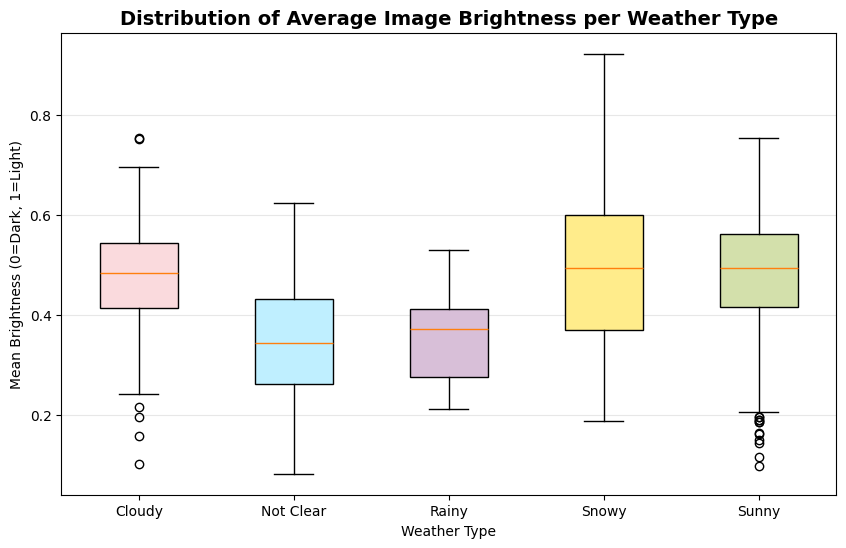

In [ ]:
#Lower outliers :Image is much darker than most images of that weather type
#Upper outliers:Image is much brighter than most images of that weather type.

PROCESSED_FOLDER = "processed_images"
# Using your specific colors
COLORS = {
    'Sunny': '#D3E0AB',
    'Cloudy': '#FADADD',
    'Rainy': '#D8BFD8',
    'Snowy': '#FFEC8B',
    'Not Clear': '#BFEFFF'
}

brightness_by_class = {}

# 1. Load data
weather_types = [d for d in os.listdir(PROCESSED_FOLDER) if os.path.isdir(os.path.join(PROCESSED_FOLDER, d))]
for weather in weather_types:
    path = os.path.join(PROCESSED_FOLDER, weather)
    # Added a limit [:100] to prevent memory issues if you have thousands of images
    files = [f for f in os.listdir(path) if f.endswith('.npy')]
    images = [np.load(os.path.join(path, f)) for f in files]

    if images:
        brightness = [img.mean() for img in images]
        brightness_by_class[weather] = brightness

# 2. Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# IMPORTANT: Capture the dictionary returned by boxplot
bplot = ax.boxplot(
    [brightness_by_class[w] for w in brightness_by_class],
    labels=list(brightness_by_class.keys()),
    patch_artist=True  # Required to fill with color
)

# 3. FIX: Apply colors using the 'boxes' key from the dictionary
for patch, weather_name in zip(bplot['boxes'], brightness_by_class.keys()):
    color = COLORS.get(weather_name, "#808080") # Default to gray if not found
    patch.set_facecolor(color)
    patch.set_edgecolor('black') # Makes the box border visible

ax.set_title("Distribution of Average Image Brightness per Weather Type", fontsize=14, fontweight="bold")
ax.set_ylabel("Mean Brightness (0=Dark, 1=Light)")
ax.set_xlabel("Weather Type")
plt.grid(alpha=0.3, axis='y')
plt.show()

In [ ]:
#handle outliers by remove them
PROCESSED_FOLDER = "processed_images"

def remove_outliers_iqr(weather_folder):
    path = os.path.join(PROCESSED_FOLDER, weather_folder)
    files = [f for f in os.listdir(path) if f.endswith(".npy")]

    # Compute mean brightness per image
    brightness = np.array([np.mean(np.load(os.path.join(path, f))) for f in files])

    # IQR thresholds
    Q1 = np.percentile(brightness, 25)
    Q3 = np.percentile(brightness, 75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Detect outlier indices
    outlier_idx = np.where((brightness < lower) | (brightness > upper))[0]
   # print(f"{weather}: {len(outlier_idx)} outliers")


    # Remove outliers
    for idx in outlier_idx:
        os.remove(os.path.join(path, files[idx]))

    print(f"{weather_folder}: Removed {len(outlier_idx)} outlier images.")

# Apply to all weather types
for weather in os.listdir(PROCESSED_FOLDER):
    if os.path.isdir(os.path.join(PROCESSED_FOLDER, weather)):
        remove_outliers_iqr(weather)


Cloudy: Removed 0 outlier images.
Not Clear: Removed 0 outlier images.
Rainy: Removed 0 outlier images.
Snowy: Removed 0 outlier images.
Sunny: Removed 0 outlier images.


C:\Users\SS\AppData\Local\Temp\ipykernel_19680\4272559289.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(


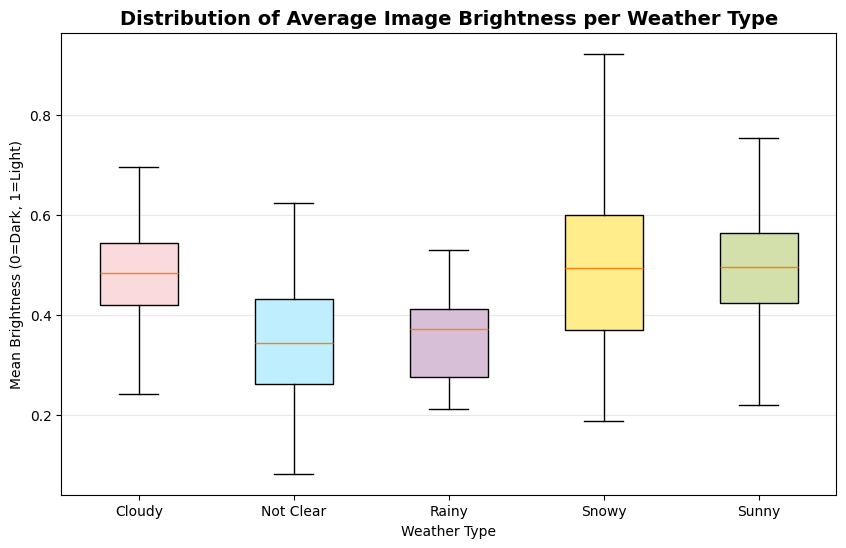

In [ ]:
#check the outliers after handle them

PROCESSED_FOLDER = "processed_images"
# Using your specific colors
COLORS = {
    'Sunny': '#D3E0AB',
    'Cloudy': '#FADADD',
    'Rainy': '#D8BFD8',
    'Snowy': '#FFEC8B',
    'Not Clear': '#BFEFFF'
}

brightness_by_class = {}

# 1. Load data
weather_types = [d for d in os.listdir(PROCESSED_FOLDER) if os.path.isdir(os.path.join(PROCESSED_FOLDER, d))]
for weather in weather_types:
    path = os.path.join(PROCESSED_FOLDER, weather)
    # Added a limit [:100] to prevent memory issues if you have thousands of images
    files = [f for f in os.listdir(path) if f.endswith('.npy')]
    images = [np.load(os.path.join(path, f)) for f in files]

    if images:
        brightness = [img.mean() for img in images]
        brightness_by_class[weather] = brightness

# 2. Plotting
fig, ax = plt.subplots(figsize=(10, 6))

# IMPORTANT: Capture the dictionary returned by boxplot
bplot = ax.boxplot(
    [brightness_by_class[w] for w in brightness_by_class],
    labels=list(brightness_by_class.keys()),
    patch_artist=True  # Required to fill with color
)

# 3. FIX: Apply colors using the 'boxes' key from the dictionary
for patch, weather_name in zip(bplot['boxes'], brightness_by_class.keys()):
    color = COLORS.get(weather_name, "#808080") # Default to gray if not found
    patch.set_facecolor(color)
    patch.set_edgecolor('black') # Makes the box border visible

ax.set_title("Distribution of Average Image Brightness per Weather Type", fontsize=14, fontweight="bold")
ax.set_ylabel("Mean Brightness (0=Dark, 1=Light)")
ax.set_xlabel("Weather Type")
plt.grid(alpha=0.3, axis='y')
plt.show()

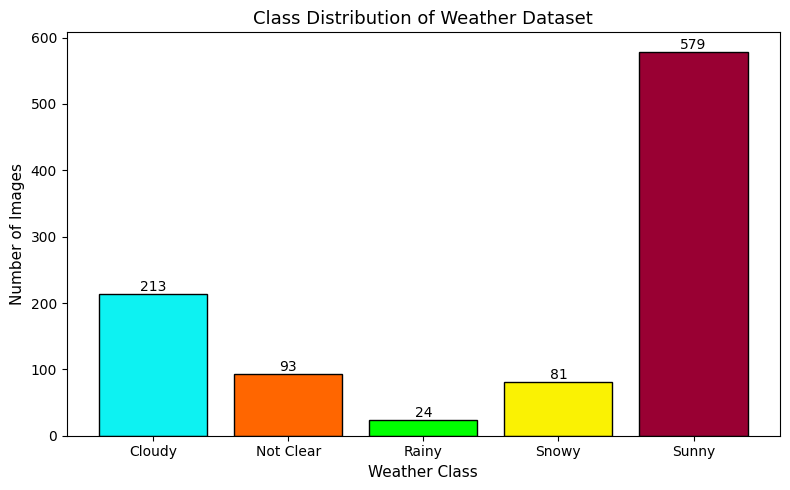

In [ ]:
# Bar chart for image numbers per class

PROCESSED_FOLDER = "processed_images"

class_counts = {}

for weather in os.listdir(PROCESSED_FOLDER):
    weather_path = os.path.join(PROCESSED_FOLDER, weather)
    if os.path.isdir(weather_path):
        num_images = len([
            f for f in os.listdir(weather_path) if f.endswith(".npy")
        ])
        class_counts[weather] = num_images

# Convert to Pandas Series (for easy plotting)
class_counts = pd.Series(class_counts).sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    class_counts.index,
    class_counts.values,
    color=['#0df2f2', '#ff6600', '#00ff00', '#faf203', '#990033'][:len(class_counts)],
    edgecolor='black'
)

# Labels and title
plt.xlabel("Weather Class", fontsize=11)
plt.ylabel("Number of Images", fontsize=11)
plt.title("Class Distribution of Weather Dataset", fontsize=13)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.tight_layout()
plt.show()



Weather      | Skewness  
-----------------------------------
Cloudy       |     0.1198
Not Clear    |     0.6090
Rainy        |     0.5986
Snowy        |     0.1131
Sunny        |    -0.0728


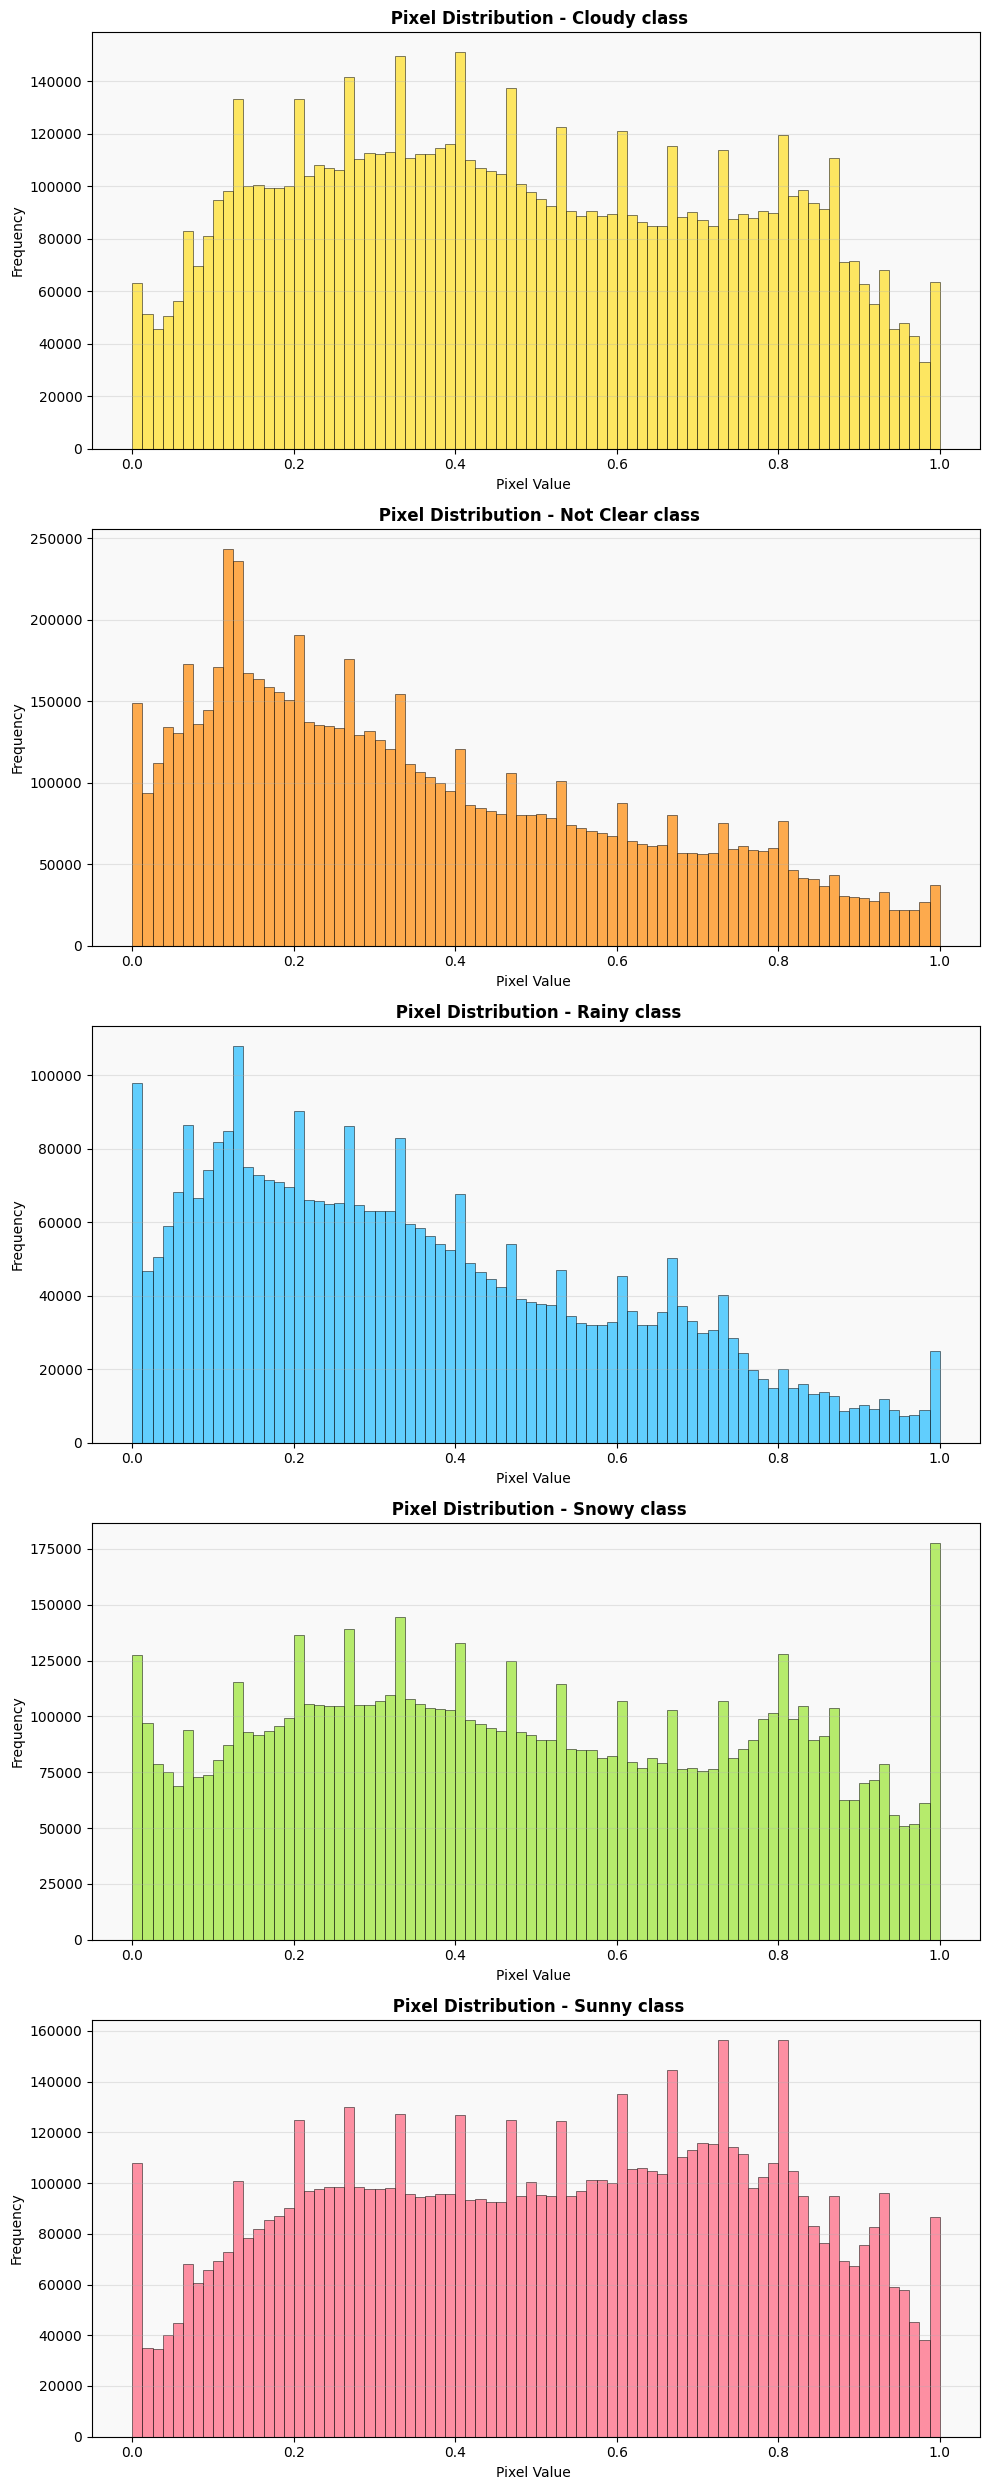

In [ ]:
#Positive Skew (Right-Skewed) = Darker Images
#Negative Skew (Left-Skewed) = Brighter Images
#Zero Skew = balanced
# pixel= (0 = dark, 1 = bright).

# Configuration
PROCESSED_FOLDER = 'processed_images'

# Define colors
colors = {
     'Sunny': '#FF637E', 'Cloudy': '#FFDF20', 'Rainy': '#21BCFF', 'Snowy': '#9AE630', 'Not Clear': '#FF8904'

}


# LOAD IMAGES AND CALCULATE SKEWNESS

images_by_class = {}
weather_folders = sorted([d for d in os.listdir(PROCESSED_FOLDER)
                          if os.path.isdir(os.path.join(PROCESSED_FOLDER, d))])

for weather in weather_folders:
    weather_path = os.path.join(PROCESSED_FOLDER, weather)
    npy_files = [f for f in os.listdir(weather_path) if f.endswith('.npy')]

    images = []
    for npy_file in npy_files[:50]:  # Load up to 50 images
        try:
            img = np.load(os.path.join(weather_path, npy_file))
            images.append(img)
        except Exception as e:
            print(f"   Error: {e}")

    images_by_class[weather] = images

print("\n")
# CREATE SEPARATE HISTOGRAM FOR EACH WEATHER TYPE

num_weather = len(images_by_class)
fig, axes = plt.subplots(num_weather, 1, figsize=(10, 5*num_weather))

# Handle single subplot case
if num_weather == 1:
    axes = [axes]

print(f"{'Weather':<12} | {'Skewness':<10}")
print("-" *35)
for idx, weather in enumerate(weather_folders):
    ax = axes[idx]
    images = images_by_class[weather]

    # Flatten all pixels
    pixels = np.concatenate([img.flatten() for img in images])
    skew_val = skew(pixels)

    # Create histogram
    ax.hist(pixels, bins=80, color=colors[weather], alpha=0.7, edgecolor='black', linewidth=0.5)

    # Add title with skewness value
    ax.set_title(f' Pixel Distribution - {weather} class', fontweight='bold')
    ax.set_xlabel('Pixel Value ', fontsize=10,)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.grid(alpha=0.3, axis='y')
    ax.set_facecolor('#f9f9f9')
    print(f"{weather:<12} | {skew_val:>10.4f}")

fig.patch.set_facecolor('#ffffff')
plt.tight_layout()
plt.show()

IMPORT ALL LIBRARIES

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
from skimage.feature import hog
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelBinarizer
# ***********
import joblib
# ************
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
print("="*70)
print("WEATHER CLASSIFICATION - CORRECTED VERSION")
print("="*70)

WEATHER CLASSIFICATION - CORRECTED VERSION


DATA LOADING

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

data_path = "/content/drive/MyDrive/processed_images"


Mounted at /content/drive


In [ ]:
class_names = [
    "Sunny",
    "Snowy",
    "Rainy",
    "Not Clear",
    "Cloudy"
]
X = []
y = []

for label, class_name in enumerate(class_names):
    class_dir = os.path.join(data_path, class_name)

    for file in os.listdir(class_dir):
        if file.endswith(".npy"):
            img = np.load(os.path.join(class_dir, file))
            img = img.flatten()     # convert image to feature vector

            X.append(img)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("Total samples:", X.shape[0])
print("Feature size:", X.shape[1])



Total samples: 990
Feature size: 150528


Standardizing Features

In [ ]:
scaler = StandardScaler()
X = scaler.fit_transform(X)


Data Splitting

In [ ]:
# First split: Train (70%) + Temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: Validation (15%) + Test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)


K-Nearest Neighbors Model Evaluation

In [ ]:
def evaluate_knn(k):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    train_acc = accuracy_score(y_train, knn.predict(X_train))
    val_acc   = accuracy_score(y_val, knn.predict(X_val))
    test_acc  = accuracy_score(y_test, knn.predict(X_test))

    print(f"K = {k}")
    print(f"Train Accuracy      : {train_acc:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print(f"Test Accuracy       : {test_acc:.4f}")
    print("-" * 40)


In [ ]:
evaluate_knn(k=1)
evaluate_knn(k=3)


K = 1
Train Accuracy      : 0.9986
Validation Accuracy : 0.5000
Test Accuracy       : 0.4765
----------------------------------------
K = 3
Train Accuracy      : 0.7302
Validation Accuracy : 0.5743
Test Accuracy       : 0.5034
----------------------------------------


In [ ]:
!ls "/content/drive/MyDrive/processed_images"


 Cloudy  'Not Clear'   Rainy   Snowy   Sunny


PCA

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=200, random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_val_pca   = pca.transform(X_val)
X_test_pca  = pca.transform(X_test)



 SVM MODEL

In [ ]:

from sklearn.preprocessing import LabelBinarizer

print("\n" + "="*70)
print("PCA + RBF SVM (BALANCED)")
print("="*70)

C_values = [0.1, 1, 10, 100]
svm_results = {}

for C in C_values:
    print(f"\nSVM with C={C}")

    svm = SVC(
        C=C,
        kernel='rbf',
        gamma='scale',
        class_weight='balanced',
        probability=True,
        random_state=42
    )

    svm.fit(X_train_pca, y_train)

    train_acc = accuracy_score(y_train, svm.predict(X_train_pca))
    val_acc   = accuracy_score(y_val, svm.predict(X_val_pca))
    test_acc  = accuracy_score(y_test, svm.predict(X_test_pca))

    print(f"Train Accuracy      : {train_acc:.4f}")
    print(f"Validation Accuracy : {val_acc:.4f}")
    print(f"Test Accuracy       : {test_acc:.4f}")

    svm_results[C] = {
        'model': svm,
        'val_acc': val_acc
    }

best_C = max(svm_results, key=lambda c: svm_results[c]['val_acc'])
best_model = svm_results[best_C]['model']

print("\n" + "="*70)
print(f"BEST MODEL → C = {best_C}")
print("="*70)

y_pred = best_model.predict(X_test_pca)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# AUC-ROC
lb = LabelBinarizer().fit(y_train)
y_test_onehot = lb.transform(y_test)
y_score = best_model.predict_proba(X_test_pca)

auc = roc_auc_score(
    y_test_onehot,
    y_score,
    multi_class='ovr'
)

print(f"AUC-ROC Score: {auc:.4f}")



PCA + RBF SVM (BALANCED)

SVM with C=0.1
Train Accuracy      : 0.3896
Validation Accuracy : 0.2905
Test Accuracy       : 0.3020

SVM with C=1
Train Accuracy      : 0.7302
Validation Accuracy : 0.4324
Test Accuracy       : 0.4564

SVM with C=10
Train Accuracy      : 0.9913
Validation Accuracy : 0.5878
Test Accuracy       : 0.5906

SVM with C=100
Train Accuracy      : 0.9971
Validation Accuracy : 0.5811
Test Accuracy       : 0.5973

BEST MODEL → C = 10

Classification Report:
              precision    recall  f1-score   support

       Sunny       0.67      0.83      0.74        87
       Snowy       0.44      0.33      0.38        12
       Rainy       0.00      0.00      0.00         4
   Not Clear       0.44      0.29      0.35        14
      Cloudy       0.33      0.25      0.29        32

    accuracy                           0.59       149
   macro avg       0.38      0.34      0.35       149
weighted avg       0.54      0.59      0.56       149

Confusion Matrix:
[[72  1  0  1

MODEL COMPARISON (KNN vs SVM)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

print("\n" + "="*70)
print("k-NN MODEL COMPARISON & ANALYSIS")
print("="*70)

knn_results = {}

for k in [1, 3]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    knn_results[k] = {
        'train_acc': accuracy_score(y_train, knn.predict(X_train)),
        'val_acc':   accuracy_score(y_val, knn.predict(X_val)),
        'test_acc':  accuracy_score(y_test, knn.predict(X_test))
    }

print("\nAccuracy Comparison:")
for k, res in knn_results.items():
    print(f"  k = {k:<2} | "
          f"Train: {res['train_acc']:.4f} | "
          f"Val: {res['val_acc']:.4f} | "
          f"Test: {res['test_acc']:.4f}")

best_k = max(knn_results, key=lambda k: knn_results[k]['val_acc'])
best_val_acc = knn_results[best_k]['val_acc']
best_test_acc = knn_results[best_k]['test_acc']

print("\n" + "-"*70)
print(f"Best k based on Validation Accuracy: k = {best_k}")
print(f"Validation Accuracy: {best_val_acc:.4f}")
print(f"Test Accuracy:       {best_test_acc:.4f}")
print("-"*70)



k-NN MODEL COMPARISON & ANALYSIS

Accuracy Comparison:
  k = 1  | Train: 0.9986 | Val: 0.5000 | Test: 0.4765
  k = 3  | Train: 0.7302 | Val: 0.5743 | Test: 0.5034

----------------------------------------------------------------------
Best k based on Validation Accuracy: k = 3
Validation Accuracy: 0.5743
Test Accuracy:       0.5034
----------------------------------------------------------------------


VISUALIZATIONS (KNN & SVM)

In [ ]:
print("\n" + "="*70)
print("GENERATING VISUALIZATIONS...")
print("="*70)

fig = plt.figure(figsize=(30, 20))


GENERATING VISUALIZATIONS...


<Figure size 3000x2000 with 0 Axes>

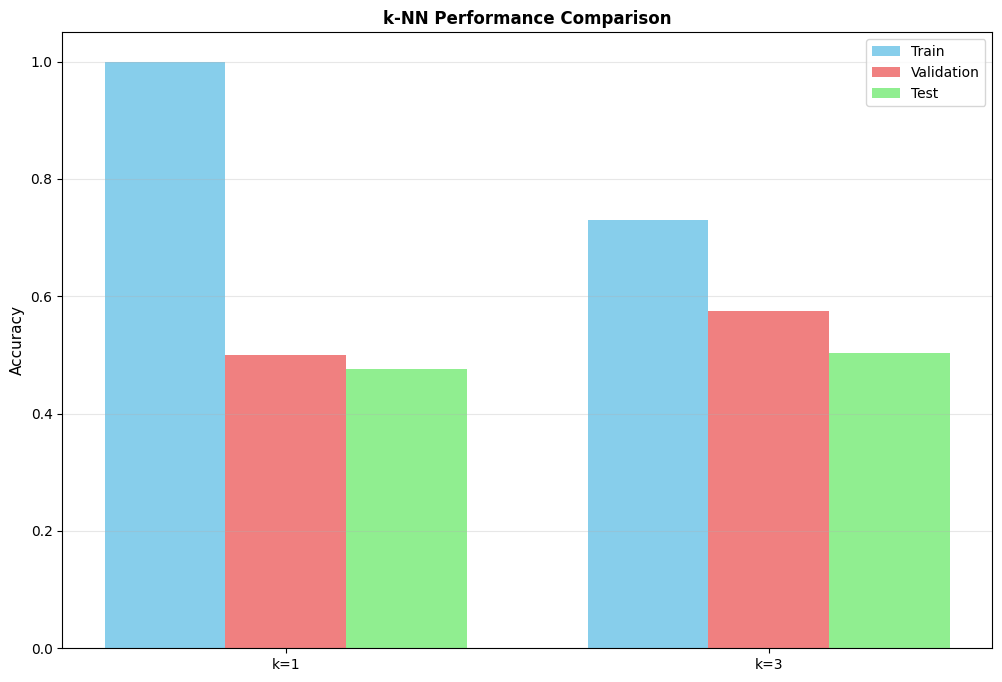

In [ ]:
# Plot 1: k-NN Comparison
fig, ax1 = plt.subplots(figsize=(12, 8))

k_vals = list(knn_results.keys())
train_acc = [knn_results[k]['train_acc'] for k in k_vals]
val_acc   = [knn_results[k]['val_acc'] for k in k_vals]
test_acc  = [knn_results[k]['test_acc'] for k in k_vals]

x = np.arange(len(k_vals))
width = 0.25

ax1.bar(x - width, train_acc, width, label='Train', color='skyblue')
ax1.bar(x, val_acc, width, label='Validation', color='lightcoral')
ax1.bar(x + width, test_acc, width, label='Test', color='lightgreen')

ax1.set_ylabel('Accuracy', fontsize=11)
ax1.set_title('k-NN Performance Comparison', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels([f'k={k}' for k in k_vals])
ax1.legend()
ax1.set_ylim([0, 1.05])
ax1.grid(True, alpha=0.3, axis='y')

plt.show()


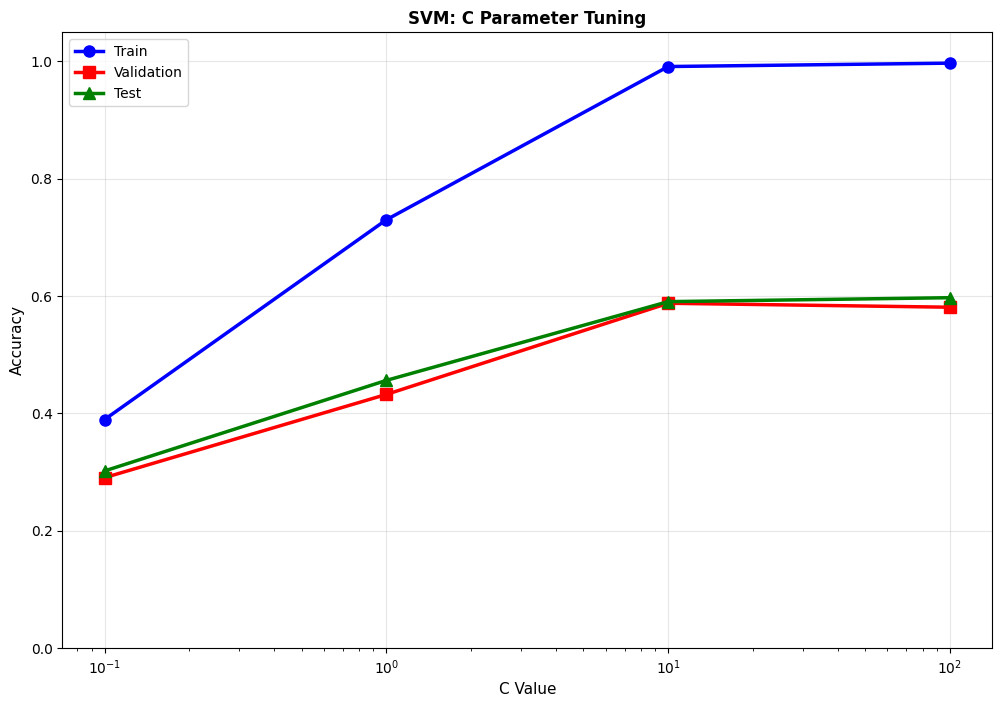

In [ ]:
# Plot 2: SVM Hyperparameter Tuning
fig, ax2 = plt.subplots(figsize=(12, 8))
c_vals = list(svm_results.keys())  # [0.1, 1, 10]
train_accs = [svm_results[c]['model'].score(X_train_pca, y_train) for c in c_vals]
val_accs   = [svm_results[c]['val_acc'] for c in c_vals]
test_accs  = [accuracy_score(y_test, svm_results[c]['model'].predict(X_test_pca)) for c in c_vals]

ax2.plot(c_vals, train_accs, marker='o', linewidth=2.5, markersize=8, label='Train', color='blue')
ax2.plot(c_vals, val_accs, marker='s', linewidth=2.5, markersize=8, label='Validation', color='red')
ax2.plot(c_vals, test_accs, marker='^', linewidth=2.5, markersize=8, label='Test', color='green')
ax2.set_xlabel('C Value', fontsize=11)
ax2.set_ylabel('Accuracy', fontsize=11)
ax2.set_title('SVM: C Parameter Tuning', fontsize=12, fontweight='bold')
ax2.set_xscale('log')
ax2.set_ylim([0, 1.05])
ax2.grid(True, alpha=0.3)
ax2.legend()

Text(0.5, 1.0, 'Best SVM (C=10) - Confusion Matrix')

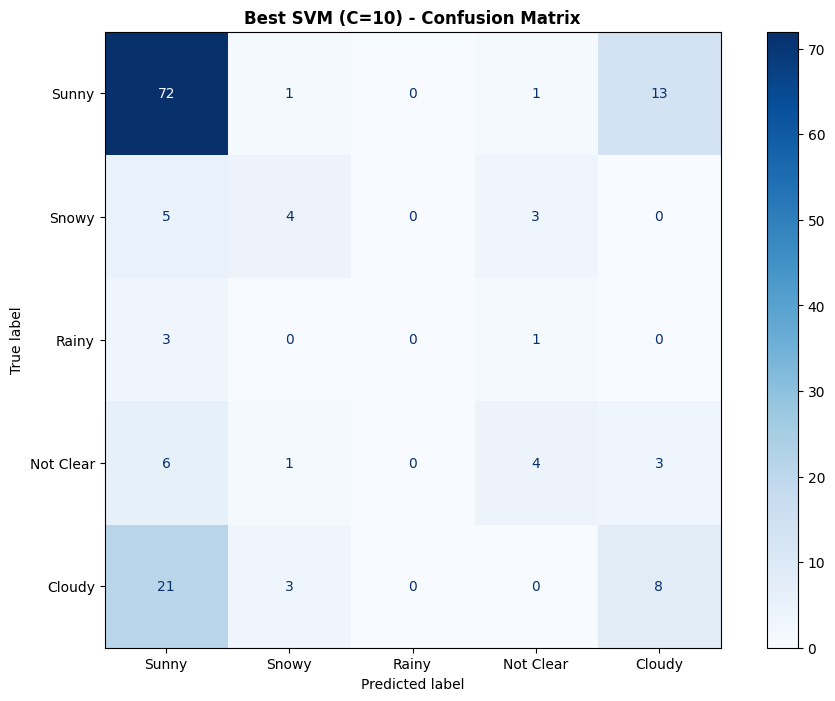

In [ ]:
# Plot 3: Best SVM Confusion Matrix
fig, ax3 = plt.subplots(figsize=(12, 8))
y_pred_best = best_model.predict(X_test_pca)
cm_best = confusion_matrix(y_test, y_pred_best)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=class_names)
disp.plot(ax=ax3, cmap='Blues', values_format='d')
ax3.set_title(f'Best SVM (C={best_C}) - Confusion Matrix', fontsize=12, fontweight='bold')


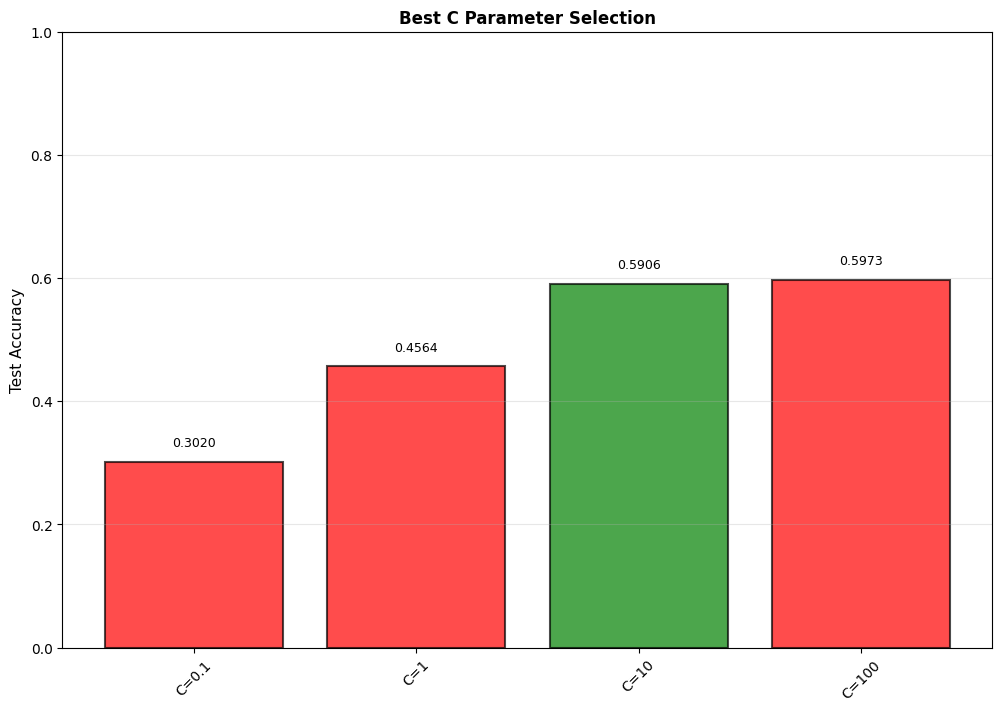

In [ ]:
# Plot 5: C Parameter Impact (Zoomed)
fig, ax5 = plt.subplots(figsize=(12, 8))
test_accs_zoom = [accuracy_score(y_test, svm_results[c]['model'].predict(X_test_pca)) for c in c_vals]
colors_c = ['green' if c == best_C else 'red' for c in c_vals]
bars = ax5.bar(range(len(c_vals)), test_accs_zoom, color=colors_c, alpha=0.7, edgecolor='black', linewidth=1.5)
ax5.set_xticks(range(len(c_vals)))
ax5.set_xticklabels([f'C={c}' for c in c_vals], rotation=45)
ax5.set_ylabel('Test Accuracy', fontsize=11)
ax5.set_title('Best C Parameter Selection', fontsize=12, fontweight='bold')
ax5.set_ylim([0, 1])
ax5.grid(True, alpha=0.3, axis='y')

for i, (bar, acc) in enumerate(zip(bars, test_accs_zoom)):
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2., height + 0.02,
             f'{acc:.4f}', ha='center', va='bottom', fontsize=9)

plt.show()


Graphs saved: model_comparison_complete.png


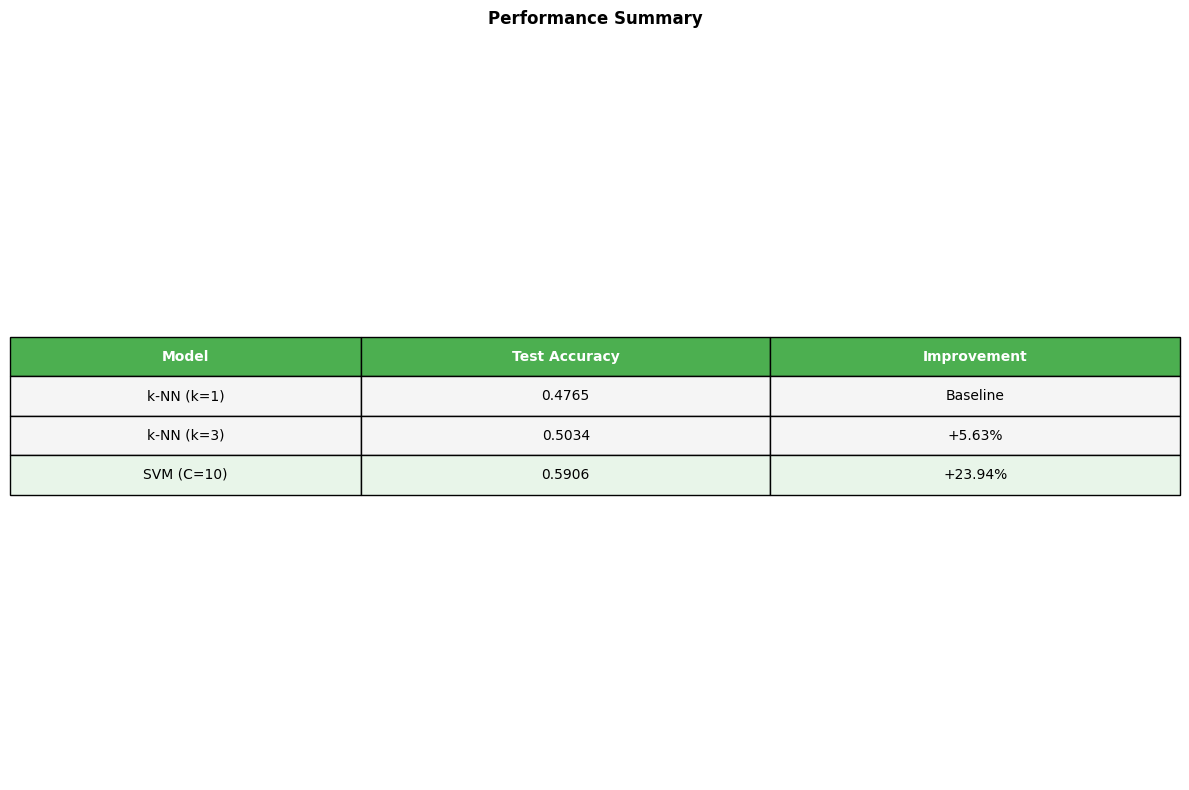


All results saved in:
  - results_baseline.txt (k-NN results)
  - results_svm.txt (SVM results)
  - model_comparison_complete.png (graphs)


In [ ]:
# Plot 6: Performance Summary Table
fig, ax6 = plt.subplots(figsize=(12, 8))
ax6.axis('off')

k1_test_acc = knn_results[1]['test_acc']
k3_test_acc = knn_results[3]['test_acc']
svm_test_acc = accuracy_score(y_test, best_model.predict(X_test_pca))

improvement_k3 = (k3_test_acc - k1_test_acc) / k1_test_acc * 100
improvement_svm = (svm_test_acc - k1_test_acc) / k1_test_acc * 100

summary_data = [
    ['Model', 'Test Accuracy', 'Improvement'],
    [f'k-NN (k=1)', f'{k1_test_acc:.4f}', 'Baseline'],
    [f'k-NN (k=3)', f'{k3_test_acc:.4f}', f'{improvement_k3:+.2f}%'],
    [f'SVM (C={best_C})', f'{svm_test_acc:.4f}', f'{improvement_svm:+.2f}%']
]

table = ax6.table(cellText=summary_data, cellLoc='center', loc='center',
                  colWidths=[0.3, 0.35, 0.35])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)

# Style header row
for i in range(3):
    table[(0, i)].set_facecolor('#4CAF50')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color data rows
for i in range(1, 4):
    for j in range(3):
        if i == 3:  # Best model row
            table[(i, j)].set_facecolor('#E8F5E9')
        else:
            table[(i, j)].set_facecolor('#F5F5F5')

ax6.set_title('Performance Summary', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('model_comparison_complete.png', dpi=300, bbox_inches='tight')
print("\nGraphs saved: model_comparison_complete.png")
plt.show()

print("\n" + "="*70)
print("All results saved in:")
print("  - results_baseline.txt (k-NN results)")
print("  - results_svm.txt (SVM results)")
print("  - model_comparison_complete.png (graphs)")
print("="*70)


Performance analysis for SVM

Misclassified

In [ ]:
y_pred = best_model.predict(X_test_pca)

misclassified_idx = np.where(y_pred != y_test)[0]

print(f"Number of misclassified samples: {len(misclassified_idx)}")


Number of misclassified samples: 61


Misclassified Samples

In [ ]:
for idx in misclassified_idx[:10]:
    print(f"Sample {idx}: True = {class_names[y_test[idx]]}, Predicted = {class_names[y_pred[idx]]}")


Sample 4: True = Cloudy, Predicted = Sunny
Sample 8: True = Cloudy, Predicted = Sunny
Sample 9: True = Cloudy, Predicted = Sunny
Sample 12: True = Sunny, Predicted = Not Clear
Sample 17: True = Sunny, Predicted = Cloudy
Sample 18: True = Not Clear, Predicted = Sunny
Sample 19: True = Sunny, Predicted = Cloudy
Sample 22: True = Cloudy, Predicted = Snowy
Sample 24: True = Sunny, Predicted = Cloudy
Sample 28: True = Cloudy, Predicted = Snowy


In [ ]:
from collections import Counter

true_labels = [class_names[y_test[i]] for i in misclassified_idx]
counter = Counter(true_labels)

print("Misclassifications per class:")
for label, count in counter.items():
    print(f"  {label}: {count}")


Misclassifications per class:
  Cloudy: 24
  Sunny: 15
  Not Clear: 10
  Snowy: 8
  Rainy: 4


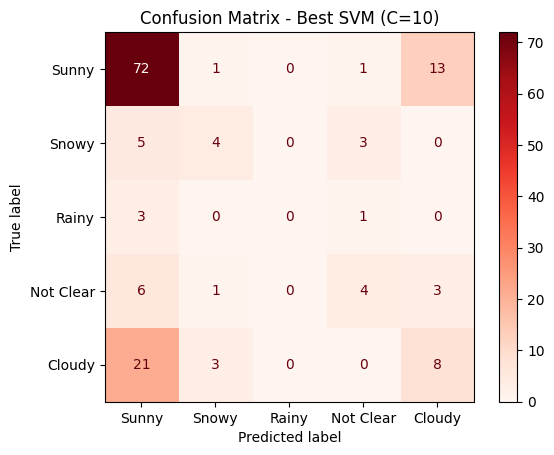

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap='Reds', values_format='d')
plt.title("Confusion Matrix - Best SVM (C=10)")
plt.show()


Misclassification Rate (%) per class:
  Sunny: 17.24%
  Snowy: 66.67%
  Rainy: 100.00%
  Not Clear: 71.43%
  Cloudy: 75.00%


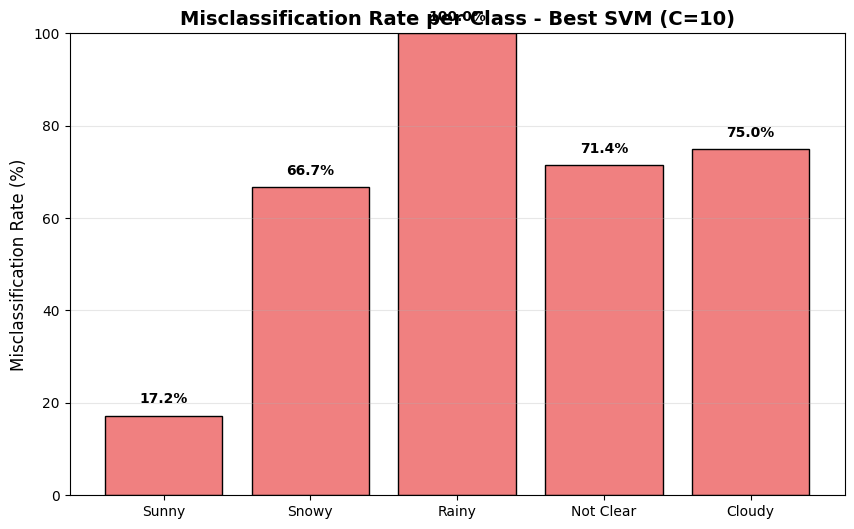

In [ ]:
from collections import defaultdict

total_per_class = defaultdict(int)
for label in y_test:
    total_per_class[class_names[label]] += 1

misclass_per_class = Counter([class_names[y_test[i]] for i in misclassified_idx])

misclass_rate = {cls: misclass_per_class.get(cls, 0) / total_per_class[cls] * 100
                 for cls in class_names}

print("Misclassification Rate (%) per class:")
for cls in class_names:
    print(f"  {cls}: {misclass_rate[cls]:.2f}%")

plt.figure(figsize=(10,6))
bars = plt.bar(misclass_rate.keys(), misclass_rate.values(), color='lightcoral', edgecolor='black')
plt.ylabel('Misclassification Rate (%)', fontsize=12)
plt.title('Misclassification Rate per Class - Best SVM (C=10)', fontsize=14, fontweight='bold')
plt.ylim([0, 100])
plt.grid(axis='y', alpha=0.3)

for bar, rate in zip(bars, misclass_rate.values()):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.show()


CNN

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


CNN Model for .npy Image Classification: Hyperparameter Search, Data Augmentation, and Performance Metrics

Total samples: 990
Sunny 579
Cloudy 213
Rainy 24
Snowy 81
Not Clear 93

Split sizes:
Train: 692  Val: 149  Test: 149

Class weights: {0: 0.3417283950617284, 1: 0.9288590604026845, 2: 8.65, 3: 2.4280701754385965, 4: 2.129230769230769}

Training with learning rate = 0.001
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.2401 - loss: 1.6369
val_macro_f1=0.2892 | val_macro_precision=0.3012 | val_macro_recall=0.3216
22/22 ━━━━━━━━━━━━━━━━━━━━ 94s 3s/step - accuracy: 0.2416 - loss: 1.6364 - val_accuracy: 0.4161 - val_loss: 1.4007 - learning_rate: 0.0010 - val_macro_f1: 0.2892 - val_macro_precision: 0.3012 - val_macro_recall: 0.3216
Epoch 2/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.3502 - loss: 1.4210
val_macro_f1=0.3447 | val_macro_precision=0.3615 | val_macro_recall=0.3429
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 226ms/step - accuracy: 0.3507 - loss: 1.4208 - val_accuracy: 0.4899 - val_loss: 1.2551 - learning_rate: 0.0010


val_macro_f1=0.1519 | val_macro_precision=0.1950 | val_macro_recall=0.1686
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 578ms/step - accuracy: 0.1514 - loss: 1.7980 - val_accuracy: 0.1879 - val_loss: 1.6422 - learning_rate: 3.0000e-04 - val_macro_f1: 0.1519 - val_macro_precision: 0.1950 - val_macro_recall: 0.1686
Epoch 2/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2688 - loss: 1.6540
val_macro_f1=0.2664 | val_macro_precision=0.2914 | val_macro_recall=0.2900
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 287ms/step - accuracy: 0.2689 - loss: 1.6525 - val_accuracy: 0.3356 - val_loss: 1.5568 - learning_rate: 3.0000e-04 - val_macro_f1: 0.2664 - val_macro_precision: 0.2914 - val_macro_recall: 0.2900
Epoch 3/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2915 - loss: 1.5723
val_macro_f1=0.3046 | val_macro_precision=0.3285 | val_macro_recall=0.3342
22/22 ━━━━━━━━━━━━━━━━━━━━ 9s 210ms/step - accuracy: 0.2925 - loss: 1.5727 - val_accuracy: 0.3691 - val_loss: 1.4931 - learning_rate: 3.0000e-04 - val_


val_macro_f1=0.1111 | val_macro_precision=0.1689 | val_macro_recall=0.1175
22/22 ━━━━━━━━━━━━━━━━━━━━ 22s 574ms/step - accuracy: 0.2203 - loss: 1.6963 - val_accuracy: 0.1812 - val_loss: 1.6515 - learning_rate: 1.0000e-04 - val_macro_f1: 0.1111 - val_macro_precision: 0.1689 - val_macro_recall: 0.1175
Epoch 2/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.2545 - loss: 1.8206
val_macro_f1=0.1262 | val_macro_precision=0.1871 | val_macro_recall=0.1302
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 205ms/step - accuracy: 0.2546 - loss: 1.8150 - val_accuracy: 0.1946 - val_loss: 1.6327 - learning_rate: 1.0000e-04 - val_macro_f1: 0.1262 - val_macro_precision: 0.1871 - val_macro_recall: 0.1302
Epoch 3/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 177ms/step - accuracy: 0.2205 - loss: 1.6408
val_macro_f1=0.1297 | val_macro_precision=0.1902 | val_macro_recall=0.1325
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 264ms/step - accuracy: 0.2211 - loss: 1.6414 - val_accuracy: 0.2013 - val_loss: 1.6134 - learning_rate: 1.0000e-04 - val_

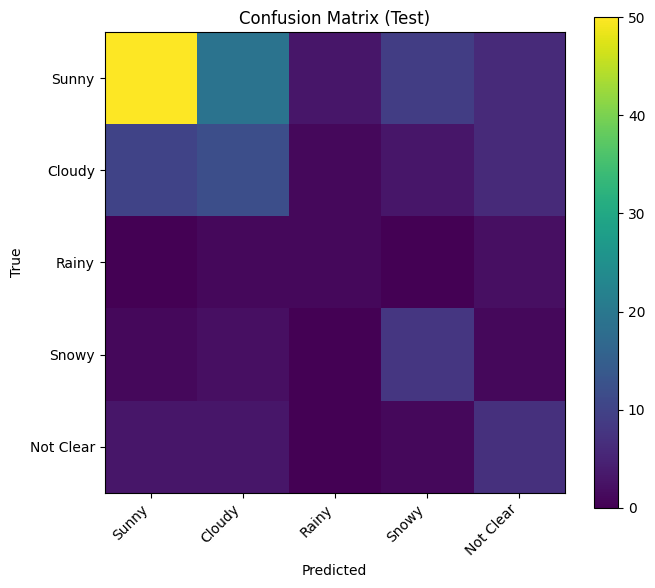

In [ ]:
# ===========================
# CNN for .npy class folders
# Hyperparameter search: Learning Rate (4 values)
# Train/Val/Test + Augment + Class Weights
# Metrics: accuracy + precision/recall/F1 (macro + per-class) + confusion matrix
# ===========================

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ====== EDIT HERE ======
DATA_DIR = Path("/content/drive/MyDrive/processed_images")  # folder contains class folders
CLASS_NAMES = ["Sunny", "Cloudy", "Rainy", "Snowy", "Not Clear"]
IMG_SIZE = 224
BATCH_SIZE = 32
# =======================

AUTOTUNE = tf.data.AUTOTUNE


# ---------- Collect paths + labels ----------
def collect_paths_and_labels(data_dir: Path, class_names):
    all_paths, all_labels = [], []
    for i, cls in enumerate(class_names):
        cls_dir = data_dir / cls
        if not cls_dir.exists():
            raise FileNotFoundError(f"Missing folder: {cls_dir}")
        files = sorted(cls_dir.glob("*.npy"))
        all_paths.extend([str(p) for p in files])
        all_labels.extend([i] * len(files))
    return np.array(all_paths), np.array(all_labels, dtype=np.int32)

paths, labels = collect_paths_and_labels(DATA_DIR, CLASS_NAMES)
print("Total samples:", len(paths))
for i, cls in enumerate(CLASS_NAMES):
    print(cls, (labels == i).sum())


# ---------- Stratified split: Train/Val/Test ----------
X_temp, X_test, y_temp, y_test = train_test_split(
    paths, labels, test_size=0.15, random_state=SEED, stratify=labels
)
val_ratio_of_temp = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio_of_temp, random_state=SEED, stratify=y_temp
)

print("\nSplit sizes:")
print("Train:", len(X_train), " Val:", len(X_val), " Test:", len(X_test))


# ---------- Class weights (important for imbalance) ----------
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights)}
print("\nClass weights:", class_weight_dict)


# ---------- Load .npy inside tf.data (FIXED for EfficientNet) ----------
# Important: EfficientNet preprocess_input works best when input is in 0..255 (float)
def load_npy(path):
    def _loader(p):
        arr = np.load(p.decode("utf-8")).astype(np.float32)

        # Make it ALWAYS 0..255
        mx = float(arr.max()) if arr.size else 0.0
        if mx <= 1.5:          # likely 0..1
            arr = arr * 255.0  # convert to 0..255
        # else: already 0..255 -> keep

        # Ensure shape is (224,224,3)
        if arr.shape != (IMG_SIZE, IMG_SIZE, 3):
            raise ValueError(f"Bad shape {arr.shape}, expected {(IMG_SIZE, IMG_SIZE, 3)}")

        return arr

    img = tf.numpy_function(_loader, [path], Tout=tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img


def make_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(buffer_size=len(X), seed=SEED, reshuffle_each_iteration=True)

    def _map(path, label):
        img = load_npy(path)
        label_oh = tf.one_hot(label, depth=len(CLASS_NAMES))
        return img, label_oh

    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val, y_val, training=False)
test_ds  = make_dataset(X_test, y_test, training=False)


# ---------- Augmentation ----------
data_augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15),
], name="augment")


# ---------- Optional: show one sample ----------
def show_sample():
    x0, y0 = next(iter(train_ds.take(1)))
    img = x0[0].numpy()
    label = np.argmax(y0[0].numpy())
    print("Sample stats:", img.min(), img.max(), img.dtype, "Label:", CLASS_NAMES[label])
    plt.figure(figsize=(4,4))
    plt.imshow(np.clip(img/255.0, 0, 1))  # display
    plt.title(CLASS_NAMES[label])
    plt.axis("off")
    plt.show()

# Uncomment if you want to see a sample:
# show_sample()


# ---------- Val metrics callback (Macro F1/Precision/Recall) ----------
class ValMetricsCallback(tf.keras.callbacks.Callback):
    def __init__(self, val_ds):
        super().__init__()
        self.val_ds = val_ds

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        y_true, y_pred = [], []

        for xb, yb in self.val_ds:
            probs = self.model.predict(xb, verbose=0)
            y_pred.append(np.argmax(probs, axis=1))
            y_true.append(np.argmax(yb.numpy(), axis=1))

        y_true = np.concatenate(y_true)
        y_pred = np.concatenate(y_pred)

        logs["val_macro_f1"] = f1_score(y_true, y_pred, average="macro")
        logs["val_macro_precision"] = precision_score(y_true, y_pred, average="macro", zero_division=0)
        logs["val_macro_recall"] = recall_score(y_true, y_pred, average="macro", zero_division=0)

        print(f"\nval_macro_f1={logs['val_macro_f1']:.4f} | "
              f"val_macro_precision={logs['val_macro_precision']:.4f} | "
              f"val_macro_recall={logs['val_macro_recall']:.4f}")


# ---------- Model builder ----------
def build_model(learning_rate=1e-3, dropout=0.45):
    base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = False  # stage 1

    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = data_augment(inputs)
    x = tf.keras.applications.efficientnet.preprocess_input(x)  # expects 0..255 float
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base


# ---------- Predict labels ----------
def predict_labels(model, ds):
    probs = model.predict(ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)

    y_true = []
    for _, yb in ds:
        y_true.append(np.argmax(yb.numpy(), axis=1))
    y_true = np.concatenate(y_true)
    return y_true, y_pred


# ---------- Train function (2 stages) ----------
def train_one_lr(lr):
    model, base = build_model(learning_rate=lr, dropout=0.4)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.3, min_lr=1e-6),
        ValMetricsCallback(val_ds)
    ]

    # Stage 1: train head
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=1
    )

    # Stage 2: fine-tune last layers
    base.trainable = True
    for layer in base.layers[:-15]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr * 0.1),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=1
    )

    y_true, y_pred = predict_labels(model, val_ds)
    val_macro_f1 = f1_score(y_true, y_pred, average="macro")
    val_acc = (y_true == y_pred).mean()

    return model, val_macro_f1, val_acc


# ===========================
# Hyperparameter search (ONE hyperparameter: learning rate) with 4 values (SAFER)
# ===========================
lr_values = [1e-3, 3e-4, 1e-4, 3e-5]  # 4 values (recommended)
results = []

best_model = None
best_lr = None
best_f1 = -1

for lr in lr_values:
    print("\n" + "="*60)
    print("Training with learning rate =", lr)
    model, val_f1, val_acc = train_one_lr(lr)
    print(f"Val Accuracy: {val_acc:.4f} | Val Macro F1: {val_f1:.4f}")

    results.append((lr, val_acc, val_f1))
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_lr = lr
        best_model = model

print("\nResults (lr, val_acc, val_macro_f1):")
for r in results:
    print(r)

print("\nBEST LR =", best_lr, "with Val Macro F1 =", best_f1)


# ===========================
# Final evaluation on TEST using the best model
# ===========================
y_true_test, y_pred_test = predict_labels(best_model, test_ds)

print("\n--- TEST Classification Report ---")
print(classification_report(
    y_true_test, y_pred_test, target_names=CLASS_NAMES, digits=4
))

print("\n--- Confusion Matrix (TEST) ---")
cm = confusion_matrix(y_true_test, y_pred_test)
print(cm)

plt.figure(figsize=(7,6))
plt.imshow(cm)
plt.title("Confusion Matrix (Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.tight_layout()
plt.show()


Confusion Matrix _ CNN

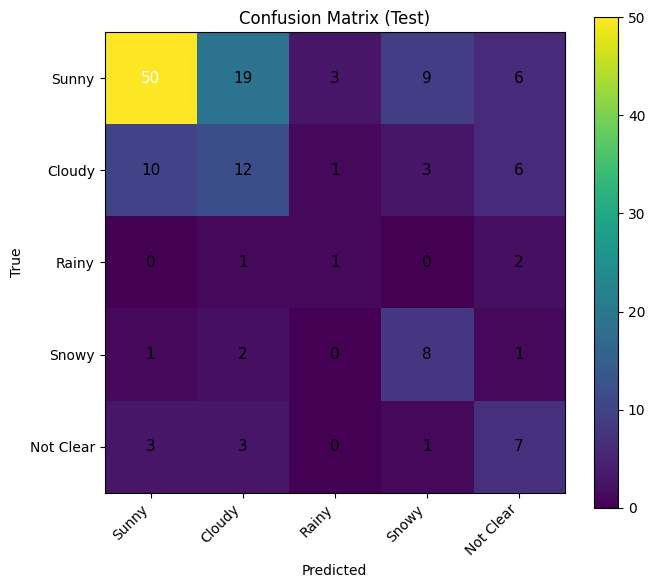

In [ ]:
plt.figure(figsize=(7,6))
plt.imshow(cm, cmap="viridis")
plt.title("Confusion Matrix (Test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.colorbar()

plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45, ha="right")
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, cm[i, j],
            ha="center", va="center",
            color="white" if cm[i, j] > cm.max()/2 else "black",
            fontsize=11
        )

plt.tight_layout()
plt.show()


CNN for .npy Image Classification with Hyperparameter Search, Augmentation, Class Weights, and Performance Metrics (Loss & Accuracy Plots

Epoch 1/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.2524 - loss: 1.7923val_macro_f1=0.2503
22/22 ━━━━━━━━━━━━━━━━━━━━ 28s 766ms/step - accuracy: 0.2520 - loss: 1.7903 - val_accuracy: 0.3356 - val_loss: 1.5111 - learning_rate: 0.0010
Epoch 2/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step - accuracy: 0.3241 - loss: 1.4145val_macro_f1=0.3025
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 356ms/step - accuracy: 0.3241 - loss: 1.4151 - val_accuracy: 0.4161 - val_loss: 1.3773 - learning_rate: 0.0010
Epoch 3/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 236ms/step - accuracy: 0.3826 - loss: 1.3978val_macro_f1=0.3348
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 379ms/step - accuracy: 0.3829 - loss: 1.3975 - val_accuracy: 0.4362 - val_loss: 1.2976 - learning_rate: 0.0010
Epoch 4/12
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 0.4458 - loss: 1.1533val_macro_f1=0.3873
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 388ms/step - accuracy: 0.4464 - loss: 1.1557 - val_accuracy: 0.5034 - val_loss: 1.2410 - learning_rate: 0.0010
Epoch 5/12
22/2

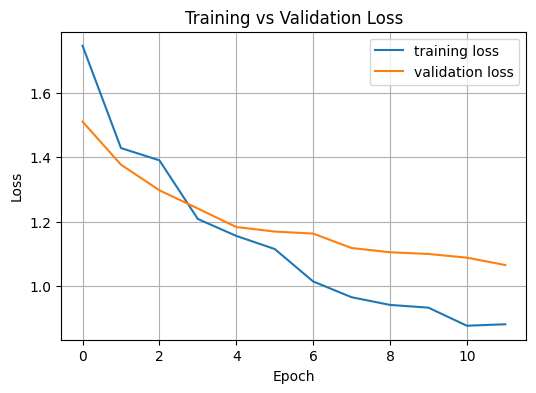

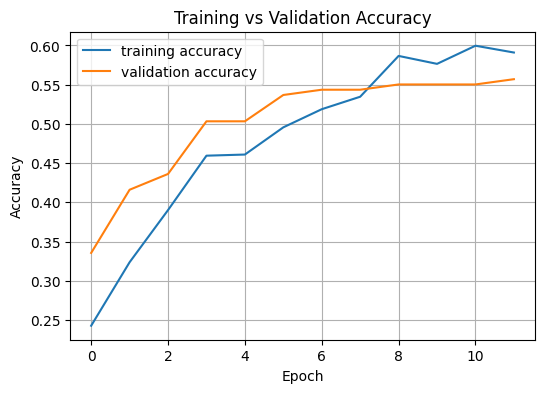

              precision    recall  f1-score   support

       Sunny       0.81      0.53      0.64        87
      Cloudy       0.35      0.44      0.39        32
       Rainy       0.20      0.25      0.22         4
       Snowy       0.36      0.75      0.49        12
   Not Clear       0.27      0.43      0.33        14

    accuracy                           0.51       149
   macro avg       0.40      0.48      0.41       149
weighted avg       0.61      0.51      0.53       149



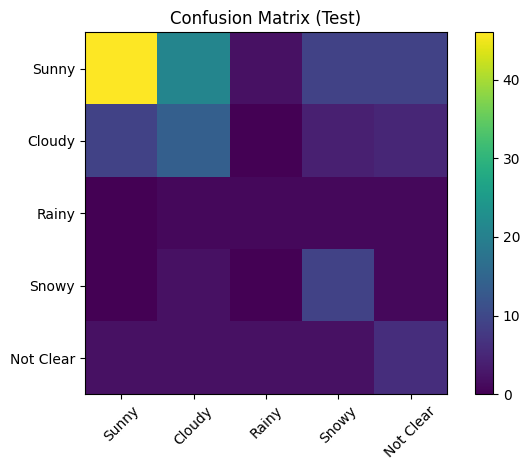

In [ ]:
# ===========================
# CNN for .npy class folders
# Hyperparameter search: Learning Rate (4 values)
# Train/Val/Test + Augment + Class Weights
# Metrics: accuracy + precision/recall/F1 (macro + per-class) + confusion matrix
# + Training/Validation Loss & Accuracy plots
# ===========================

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ====== EDIT HERE ======
DATA_DIR = Path("/content/drive/MyDrive/processed_images")
CLASS_NAMES = ["Sunny", "Cloudy", "Rainy", "Snowy", "Not Clear"]
IMG_SIZE = 224
BATCH_SIZE = 32
# =======================

AUTOTUNE = tf.data.AUTOTUNE


# ---------- Collect paths + labels ----------
def collect_paths_and_labels(data_dir: Path, class_names):
    all_paths, all_labels = [], []
    for i, cls in enumerate(class_names):
        cls_dir = data_dir / cls
        files = sorted(cls_dir.glob("*.npy"))
        all_paths.extend([str(p) for p in files])
        all_labels.extend([i] * len(files))
    return np.array(all_paths), np.array(all_labels, dtype=np.int32)

paths, labels = collect_paths_and_labels(DATA_DIR, CLASS_NAMES)


# ---------- Stratified split ----------
X_temp, X_test, y_temp, y_test = train_test_split(
    paths, labels, test_size=0.15, random_state=SEED, stratify=labels
)
val_ratio_of_temp = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio_of_temp, random_state=SEED, stratify=y_temp
)


# ---------- Class weights ----------
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights)}


# ---------- Load .npy ----------
def load_npy(path):
    def _loader(p):
        arr = np.load(p.decode("utf-8")).astype(np.float32)
        if arr.max() <= 1.5:
            arr *= 255.0
        return arr
    img = tf.numpy_function(_loader, [path], tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img


def make_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED)
    def _map(path, label):
        img = load_npy(path)
        label = tf.one_hot(label, depth=len(CLASS_NAMES))
        return img, label
    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, True)
val_ds   = make_dataset(X_val, y_val)
test_ds  = make_dataset(X_test, y_test)


# ---------- Augmentation ----------
data_augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15),
])


# ---------- Validation metrics callback ----------
class ValMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        y_true, y_pred = [], []
        for xb, yb in val_ds:
            p = self.model.predict(xb, verbose=0)
            y_pred.append(np.argmax(p, axis=1))
            y_true.append(np.argmax(yb.numpy(), axis=1))
        y_true = np.concatenate(y_true)
        y_pred = np.concatenate(y_pred)
        print(
            f"val_macro_f1={f1_score(y_true,y_pred,average='macro'):.4f}"
        )


# ---------- Model ----------
def build_model(lr=1e-3, dropout=0.45):
    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = data_augment(inputs)
    x = tf.keras.applications.efficientnet.preprocess_input(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base


# ---------- Training ----------
def train_one_lr(lr):
    model, base = build_model(lr)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.3),
        ValMetricsCallback()
    ]

    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )

    base.trainable = True
    for layer in base.layers[:-15]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr * 0.1),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )

    return model, history1, history2


# ---------- Run ----------
best_model, h1, h2 = train_one_lr(1e-3)


# ---------- PLOTS ----------
plt.figure(figsize=(6,4))
plt.plot(h1.history["loss"], label="training loss")
plt.plot(h1.history["val_loss"], label="validation loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(h1.history["accuracy"], label="training accuracy")
plt.plot(h1.history["val_accuracy"], label="validation accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# ---------- Test evaluation ----------
def predict_labels(model, ds):
    probs = model.predict(ds, verbose=0)# ===========================
# CNN for .npy class folders
# Hyperparameter search: Learning Rate (4 values)
# Train/Val/Test + Augment + Class Weights
# Metrics: accuracy + precision/recall/F1 (macro + per-class) + confusion matrix
# + Training/Validation Loss & Accuracy plots
# ===========================

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ====== EDIT HERE ======
DATA_DIR = Path("/content/drive/MyDrive/processed_images")
CLASS_NAMES = ["Sunny", "Cloudy", "Rainy", "Snowy", "Not Clear"]
IMG_SIZE = 224
BATCH_SIZE = 32
# =======================

AUTOTUNE = tf.data.AUTOTUNE


# ---------- Collect paths + labels ----------
def collect_paths_and_labels(data_dir: Path, class_names):
    all_paths, all_labels = [], []
    for i, cls in enumerate(class_names):
        cls_dir = data_dir / cls
        files = sorted(cls_dir.glob("*.npy"))
        all_paths.extend([str(p) for p in files])
        all_labels.extend([i] * len(files))
    return np.array(all_paths), np.array(all_labels, dtype=np.int32)

paths, labels = collect_paths_and_labels(DATA_DIR, CLASS_NAMES)


# ---------- Stratified split ----------
X_temp, X_test, y_temp, y_test = train_test_split(
    paths, labels, test_size=0.15, random_state=SEED, stratify=labels
)
val_ratio_of_temp = 0.15 / 0.85
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=val_ratio_of_temp, random_state=SEED, stratify=y_temp
)


# ---------- Class weights ----------
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights)}


# ---------- Load .npy ----------
def load_npy(path):
    def _loader(p):
        arr = np.load(p.decode("utf-8")).astype(np.float32)
        if arr.max() <= 1.5:
            arr *= 255.0
        return arr
    img = tf.numpy_function(_loader, [path], tf.float32)
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img


def make_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED)
    def _map(path, label):
        img = load_npy(path)
        label = tf.one_hot(label, depth=len(CLASS_NAMES))
        return img, label
    ds = ds.map(_map, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, True)
val_ds   = make_dataset(X_val, y_val)
test_ds  = make_dataset(X_test, y_test)


# ---------- Augmentation ----------
data_augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.15),
])


# ---------- Validation metrics callback ----------
class ValMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        y_true, y_pred = [], []
        for xb, yb in val_ds:
            p = self.model.predict(xb, verbose=0)
            y_pred.append(np.argmax(p, axis=1))
            y_true.append(np.argmax(yb.numpy(), axis=1))
        y_true = np.concatenate(y_true)
        y_pred = np.concatenate(y_pred)
        print(
            f"val_macro_f1={f1_score(y_true,y_pred,average='macro'):.4f}"
        )


# ---------- Model ----------
def build_model(lr=1e-3, dropout=0.45):
    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )
    base.trainable = False

    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = data_augment(inputs)
    x = tf.keras.applications.efficientnet.preprocess_input(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs)
    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base


# ---------- Training ----------
def train_one_lr(lr):
    model, base = build_model(lr)

    callbacks = [
        tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.3),
        ValMetricsCallback()
    ]

    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=12,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )

    base.trainable = True
    for layer in base.layers[:-15]:
        layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(lr * 0.1),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        class_weight=class_weight_dict,
        callbacks=callbacks
    )

    return model, history1, history2


# ---------- Run ----------
best_model, h1, h2 = train_one_lr(1e-3)


# ---------- PLOTS ----------
plt.figure(figsize=(6,4))
plt.plot(h1.history["loss"], label="training loss")
plt.plot(h1.history["val_loss"], label="validation loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(6,4))
plt.plot(h1.history["accuracy"], label="training accuracy")
plt.plot(h1.history["val_accuracy"], label="validation accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


# ---------- Test evaluation ----------
def predict_labels(model, ds):
    probs = model.predict(ds, verbose=0)
    y_pred = np.argmax(probs, axis=1)
    y_true = []
    for _, yb in ds:
        y_true.append(np.argmax(yb.numpy(), axis=1))
    return np.concatenate(y_true), y_pred

y_true, y_pred = predict_labels(best_model, test_ds)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
cm = confusion_matrix(y_true, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix (Test)")
plt.colorbar()
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45)
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.tight_layout()
plt.show()

    y_pred = np.argmax(probs, axis=1)
    y_true = []
    for _, yb in ds:
        y_true.append(np.argmax(yb.numpy(), axis=1))
    return np.concatenate(y_true), y_pred

y_true, y_pred = predict_labels(best_model, test_ds)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))
cm = confusion_matrix(y_true, y_pred)

plt.imshow(cm)
plt.title("Confusion Matrix (Test)")
plt.colorbar()
plt.xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=45)
plt.yticks(range(len(CLASS_NAMES)), CLASS_NAMES)
plt.tight_layout()
plt.show()


Misclassifications

In [ ]:
misclassified_idx = np.where(y_true_test != y_pred_test)[0]

print(f"Number of misclassified samples (Test Set): {len(misclassified_idx)} / {len(y_true_test)}")

Number of misclassified samples (Test Set): 71 / 149


Misclassified Samples

In [ ]:
for idx in misclassified_idx[:10]:
    print(f"Sample {idx}: True = {CLASS_NAMES[y_test[idx]]}, Predicted = {CLASS_NAMES[y_pred[idx]]}")

Sample 2: True = Sunny, Predicted = Not Clear
Sample 3: True = Cloudy, Predicted = Not Clear
Sample 4: True = Sunny, Predicted = Not Clear
Sample 5: True = Sunny, Predicted = Snowy
Sample 10: True = Sunny, Predicted = Not Clear
Sample 11: True = Sunny, Predicted = Cloudy
Sample 12: True = Sunny, Predicted = Snowy
Sample 19: True = Sunny, Predicted = Cloudy
Sample 20: True = Not Clear, Predicted = Snowy
Sample 21: True = Cloudy, Predicted = Sunny


Misclassifications per true class

In [ ]:
import pandas as pd

misclassified_labels = y_true[misclassified_idx]
misclassified_preds = y_pred[misclassified_idx]

df_errors = pd.DataFrame({
    "true_label": misclassified_labels,
    "predicted_label": misclassified_preds
})

errors_per_class = df_errors.groupby("true_label").size()
print("Misclassifications per true class:")
for i, cnt in errors_per_class.items():
    print(f"{CLASS_NAMES[i]}: {cnt}")


Misclassifications per true class:
Sunny: 41
Cloudy: 18
Rainy: 3
Snowy: 3
Not Clear: 8


Confusion Matrix for CNN

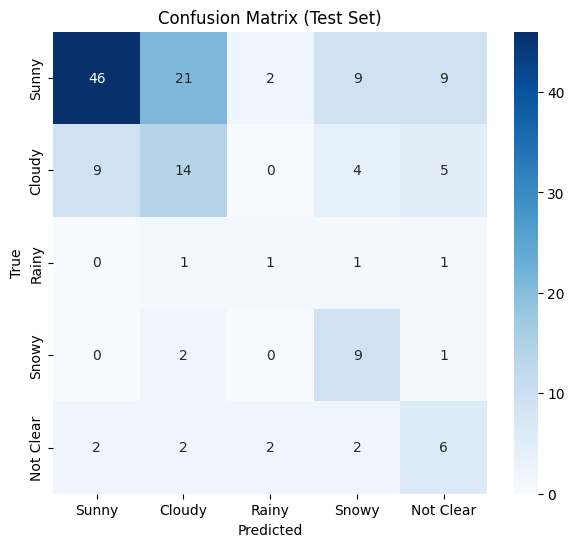

In [ ]:
import seaborn as sns

plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix (Test Set)")
plt.show()


misclassified samples

Number of misclassified samples: 71


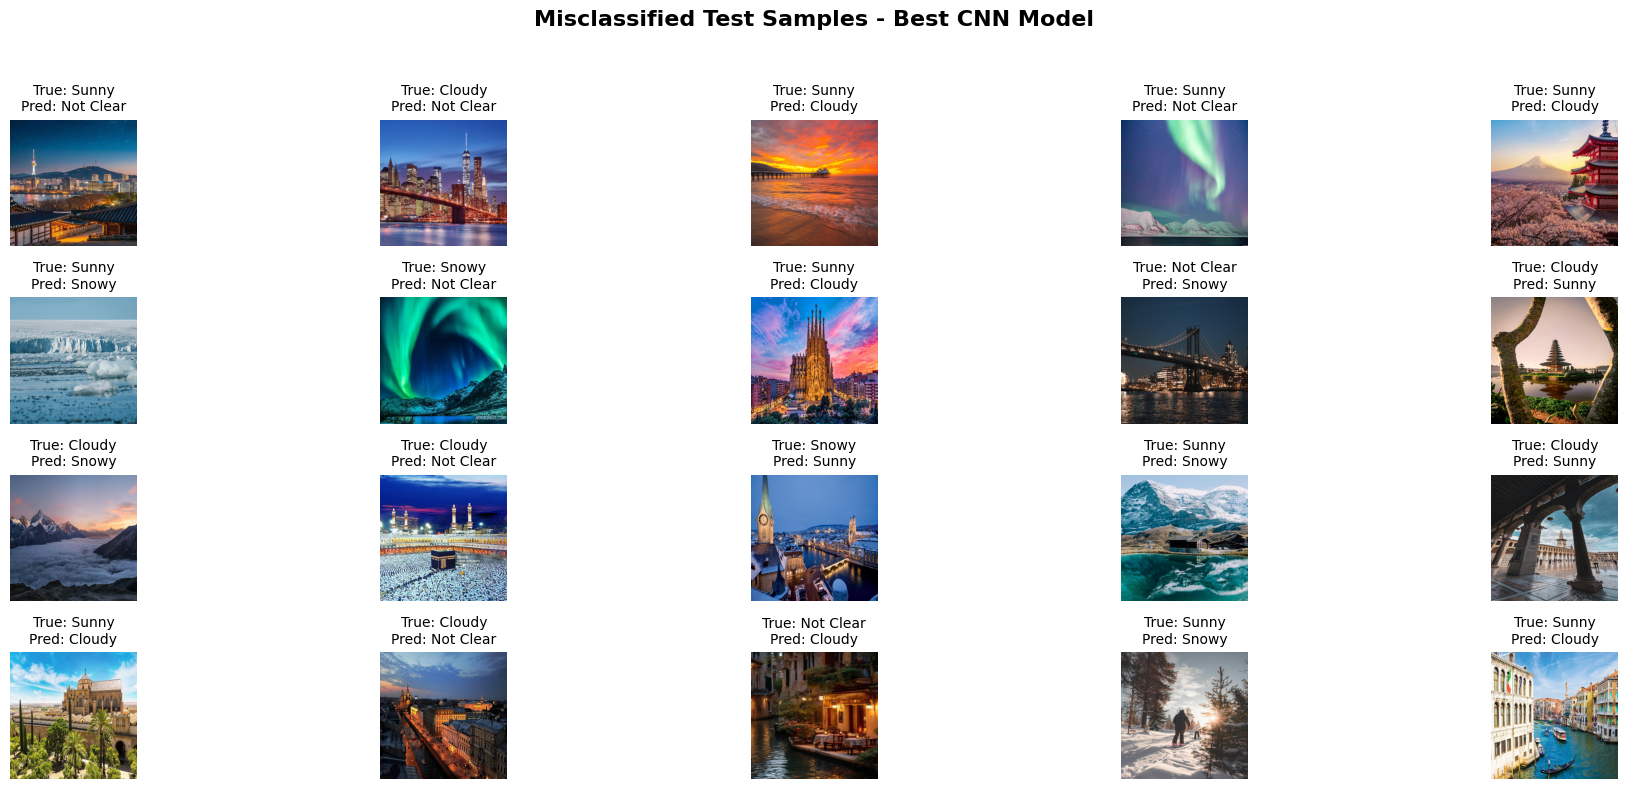

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# img_shape is already (224, 224, 3) from the global context, but good to define if not clear
img_shape = (IMG_SIZE, IMG_SIZE, 3)

# Determine misclassified samples using the pre-computed test results
misclassified_idx = np.where(y_true_test != y_pred_test)[0]
print(f"Number of misclassified samples: {len(misclassified_idx)}")

# Display the first 20 misclassified samples
num_to_show = min(20, len(misclassified_idx))
plt.figure(figsize=(20, 8))

for i, idx in enumerate(misclassified_idx[:num_to_show]):
    # Load the image
    img_path = X_test[idx]
    img = np.load(img_path).astype(np.float32)

    # Scale image for display
    min_val = img.min()
    max_val = img.max()
    if max_val > min_val:
        img_display = (img - min_val) / (max_val - min_val)  # scale to 0..1
    else:
        img_display = np.zeros_like(img)  # avoid division by zero

    true_label = CLASS_NAMES[y_true_test[idx]]
    pred_label = CLASS_NAMES[y_pred_test[idx]]

    plt.subplot(4, 5, i+1)
    plt.imshow(img_display)
    plt.title(f"True: {true_label}\nPred: {pred_label}", fontsize=10)
    plt.axis('off')

plt.suptitle("Misclassified Test Samples - Best CNN Model", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Misclassification Rate per Class Analysis

Misclassification Rate (%) per class:
  Sunny: 42.53%
  Cloudy: 62.50%
  Rainy: 75.00%
  Snowy: 33.33%
  Not Clear: 50.00%


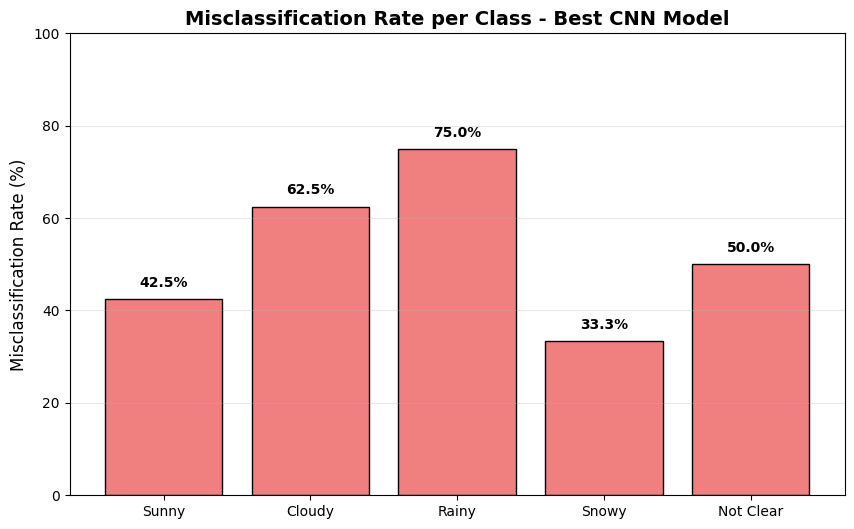

In [ ]:
from collections import defaultdict, Counter

total_per_class = defaultdict(int)
for label in y_test:
    total_per_class[CLASS_NAMES[label]] += 1

misclass_per_class = Counter([CLASS_NAMES[y_test[i]] for i in misclassified_idx])

misclass_rate = {cls: misclass_per_class.get(cls, 0) / total_per_class[cls] * 100
                 for cls in CLASS_NAMES}

print("Misclassification Rate (%) per class:")
for cls in CLASS_NAMES:
    print(f"  {cls}: {misclass_rate[cls]:.2f}%")

plt.figure(figsize=(10,6))
bars = plt.bar(misclass_rate.keys(), misclass_rate.values(), color='lightcoral', edgecolor='black')
plt.ylabel('Misclassification Rate (%)', fontsize=12)
plt.title('Misclassification Rate per Class - Best CNN Model', fontsize=14, fontweight='bold')
plt.ylim([0, 100])
plt.grid(axis='y', alpha=0.3)

for bar, rate in zip(bars, misclass_rate.values()):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{rate:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.show()

In [ ]:
from collections import Counter, defaultdict
import pandas as pd


total_per_class = defaultdict(int)
for label in y_test:
    total_per_class[CLASS_NAMES[label]] += 1

misclass_per_class = Counter([CLASS_NAMES[y_test[i]] for i in misclassified_idx])

misclass_rate = {cls: misclass_per_class.get(cls, 0) / total_per_class[cls] * 100
                 for cls in CLASS_NAMES}

report_table = pd.DataFrame({
    'Class': CLASS_NAMES,
    '# Samples (Test)': [total_per_class[cls] for cls in CLASS_NAMES],
    '# Misclassified': [misclass_per_class.get(cls, 0) for cls in CLASS_NAMES],
    'Misclassification Rate (%)': [misclass_rate[cls] for cls in CLASS_NAMES]
})


print(report_table)

       Class  # Samples (Test)  # Misclassified  Misclassification Rate (%)
0      Sunny                87               37                   42.528736
1     Cloudy                32               20                   62.500000
2      Rainy                 4                3                   75.000000
3      Snowy                12                4                   33.333333
4  Not Clear                14                7                   50.000000


Identifying Hard and Easy Samples Based on Model Confidence

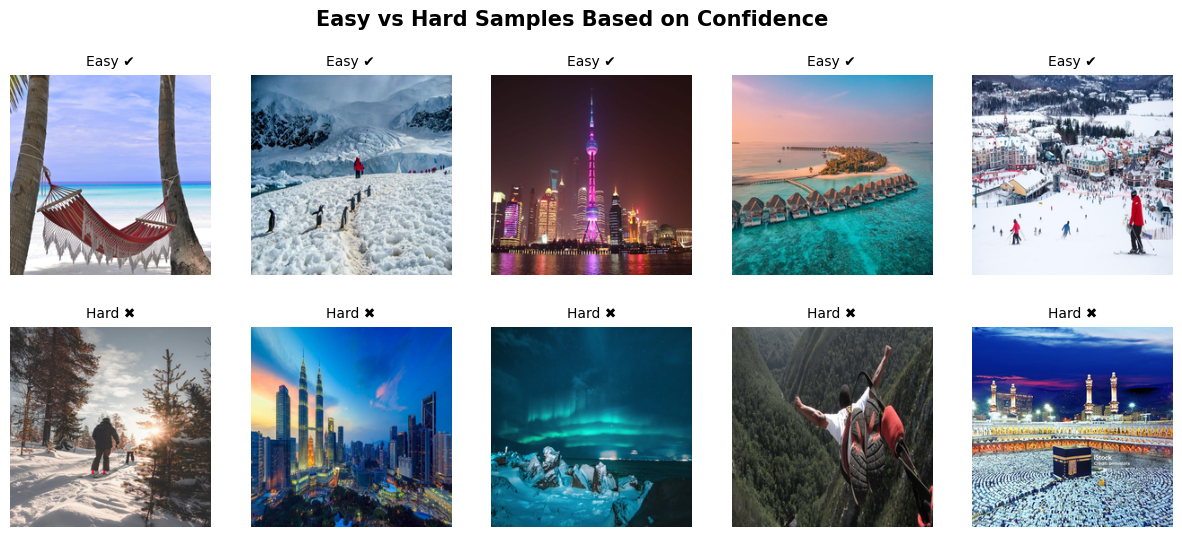

In [ ]:
idx_correct = np.where(y_true_test == y_pred_test)[0]
idx_wrong   = np.where(y_true_test != y_pred_test)[0]

hard = idx_wrong[np.argsort(-confidences[idx_wrong])][:5]
easy = idx_correct[np.argsort(-confidences[idx_correct])][:5]

plt.figure(figsize=(15,6))

for i, idx in enumerate(easy):
    img = np.load(X_test[idx])
    plt.subplot(2,5,i+1)
    plt.imshow((img-img.min())/(img.max()-img.min()))
    plt.title("Easy ✔", fontsize=10)
    plt.axis("off")

for i, idx in enumerate(hard):
    img = np.load(X_test[idx])
    plt.subplot(2,5,i+6)
    plt.imshow((img-img.min())/(img.max()-img.min()))
    plt.title("Hard ✖", fontsize=10)
    plt.axis("off")

plt.suptitle("Easy vs Hard Samples Based on Confidence", fontsize=15, fontweight="bold")
plt.show()
